## PREPARING AND CHECKING WORKING ENV

In [3]:
#check environment name and working directory
import os
print(os.environ.get('CONDA_DEFAULT_ENV')) # Example for conda environment name
print("Current working directory:", os.getcwd())

bioinfo
Current working directory: /Users/beto/progra25/analisis ecologico diabetes


# BLOQUE 1 - Exploring datasets

In [2]:
## LOADING DATASETS & CLEANING DATASETS

### LOADING ###----------###----------###----------###----------###----------###----------###----------###----------###----------###----------###----------
#conda install matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#loading datasets
d = pd.read_csv('diseases.csv',decimal='.')
n = pd.read_csv('nova_food.csv',decimal='.')
#print(d.head())
#print("NOVA TABLE: ######### " , n.head())



### CLEANING AND UNIFYING FORMAT###----------###----------###----------###----------###----------###----------###----------###----------###----------###----------###----------

import re

# Standardize column names
d.columns = d.columns.str.strip().str.lower().str.replace(" ", "_")
n.columns = n.columns.str.strip().str.lower().str.replace(" ", "_")

# Convert everything except "year" to numeric in DISEASES dataset
for col in d.columns:
    if col != "year" and col != "cases_source":
        d[col] = (
            d[col]
            .astype(str)
            .str.replace(",", "", regex=False)   # remove commas
            .str.replace(" ", "", regex=False)   # remove spaces in numbers
            .str.replace("\u202f", "", regex=False)   # remove narrow non-break space
            .str.replace("\xa0", "", regex=False)     # remove no-break space
        )
        d[col] = pd.to_numeric(d[col], errors="coerce")
        
#Explicitly ensure 'cases_source' is a string ---
d["cases_source"] = d["cases_source"].astype(str)

# Convert everything except "year" to numeric in NOVA FOODS dataset
for col in n.columns:
    if col != "year":
        n[col] = (
            n[col]
            .astype(str)
            .str.replace(",", "", regex=False)   # remove commas
            .str.replace(" ", "", regex=False)   # remove spaces in numbers
            .str.replace("\u202f", "", regex=False)   # remove narrow non-break space
            .str.replace("\xa0", "", regex=False)     # remove no-break space
        )
        # Convert to numeric
        n[col] = pd.to_numeric(n[col], errors="coerce")


#Check DISEASES dataset:
print("\n###----------###----------###----------###\nDISEASE DATASET\n###----------###----------###----------###")
print(d.info())
print(d.head())

print("\n###----------###----------###----------###----------###----------###----------###----------###----------###----------###----------###----------\n")
print("\n###----------###----------###----------###----------###----------###----------###----------###----------###----------###----------###----------\n")
      
#Check NOVA dataset:
print("\n###----------###----------###----------###\nNOVA FOODS DATASET\n###----------###----------###----------###")
print(n.info())
print(n.head())


###----------###----------###----------###
DISEASE DATASET
###----------###----------###----------###
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 21 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   year                                               30 non-null     int64  
 1   cases_diabetes_type1                               25 non-null     float64
 2   cases_diabetes_type2                               30 non-null     float64
 3   cases_diabetes_total                               30 non-null     float64
 4   cases_depression                                   11 non-null     float64
 5   cases_alzheimer                                    11 non-null     float64
 6   cases_parkinsons                                   11 non-null     float64
 7   cases_obesity                                      11 non-null     fl

## 1.1 GRAPH DATASETS

### 1.1.1 GRAPH DISEASES.CSV DATASET

In [4]:
#GET COLUMN NAMES
list(d.columns.values)

['year',
 'cases_diabetes_type1',
 'cases_diabetes_type2',
 'cases_diabetes_total',
 'cases_depression',
 'cases_alzheimer',
 'cases_parkinsons',
 'cases_obesity',
 'cases_malign_tumor_colon_and_rectum',
 'cases_malign_tumor_stomach',
 'cases_malign_tumor_encephalus_and_other_cns_parts',
 'cases_cerebrovascular_disease',
 'cases_bacterial_food_intoxication',
 'cases_brucelosis',
 'cases_ulcers_gastritis_and_duodenitis',
 'cases_hepatic_alcoholic_cirrosis',
 'cases_arterial_hypertension',
 'cases_alcoholic_liver_disease',
 'total_reported_cases',
 'population_year',
 'cases_source']

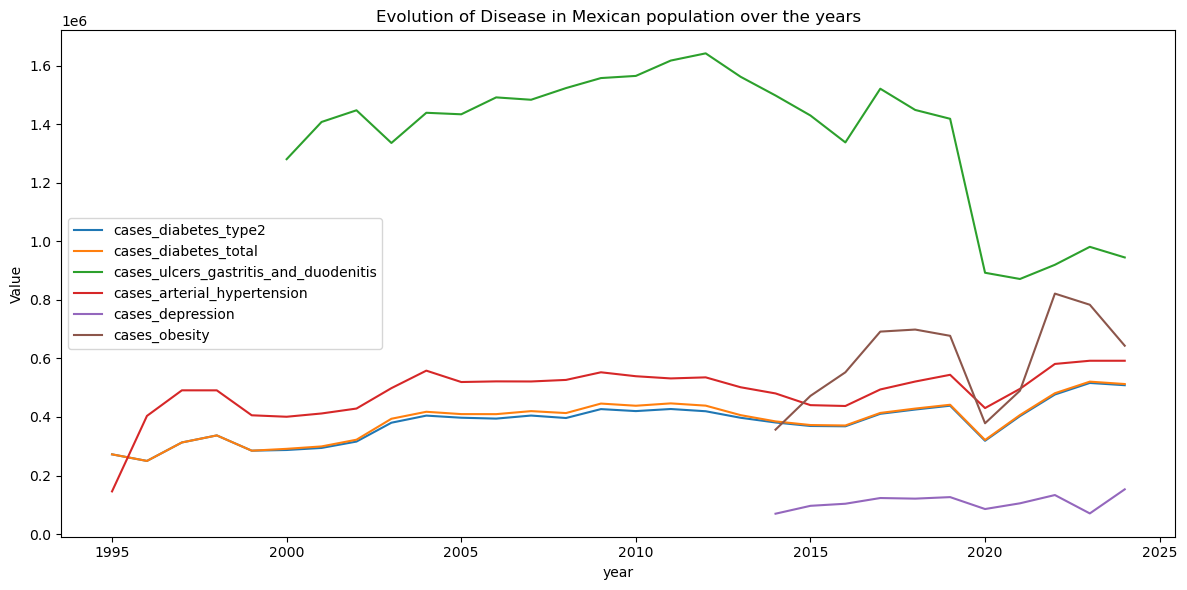

In [5]:
## 1. Columns  to plot (the Y-series)
# 0 to 1.6x(1e6)
plot_columns = [     
 'cases_diabetes_type2',
 'cases_diabetes_total',
'cases_ulcers_gastritis_and_duodenitis',
 'cases_arterial_hypertension',
    'cases_depression',
    'cases_obesity',
 
]


# 2. Plot the data using the DataFrame's plot method
# 'year' is set as the index, or x='year'
ax = d.set_index('year')[plot_columns].plot(
    figsize=(12, 6),
    title="Evolution of Disease in Mexican population over the years"
)

# 3. Add remaining labels and layout adjustments
ax.set_ylabel("Value")
ax.legend()
plt.tight_layout()
plt.show()



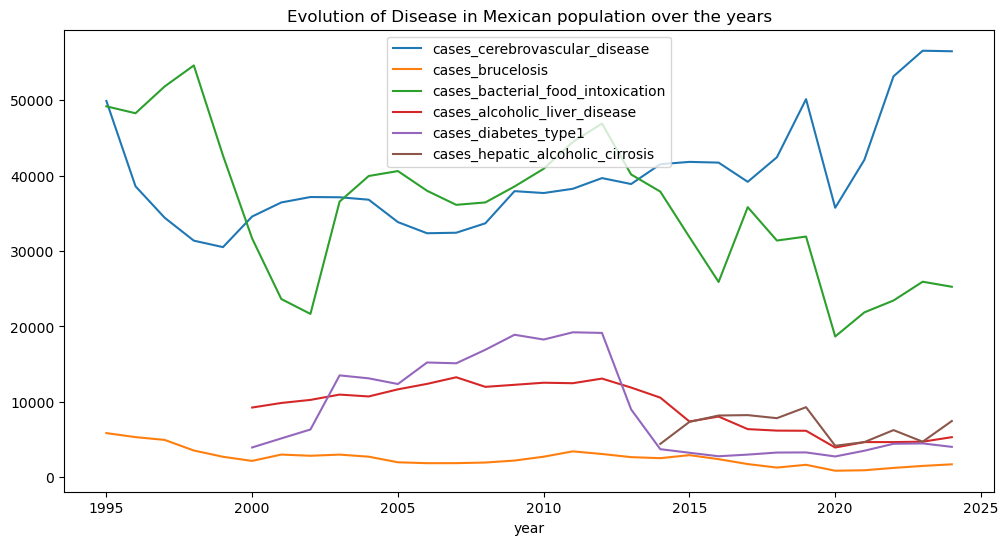

In [6]:
## 2. Columns  to plot (the Y-series)
#0 to 20,000 cases
plot_columns_lower = [ #0 
 'cases_cerebrovascular_disease', 
'cases_brucelosis',
'cases_bacterial_food_intoxication',
'cases_alcoholic_liver_disease',
'cases_diabetes_type1',
'cases_hepatic_alcoholic_cirrosis',
]


# 2. Plot the data using the DataFrame's plot method
# 'year' is set as the index, or x='year'
ax = d.set_index('year')[plot_columns_lower].plot(
    figsize=(12, 6),
    title="Evolution of Disease in Mexican population over the years"
)




<Figure size 640x480 with 0 Axes>

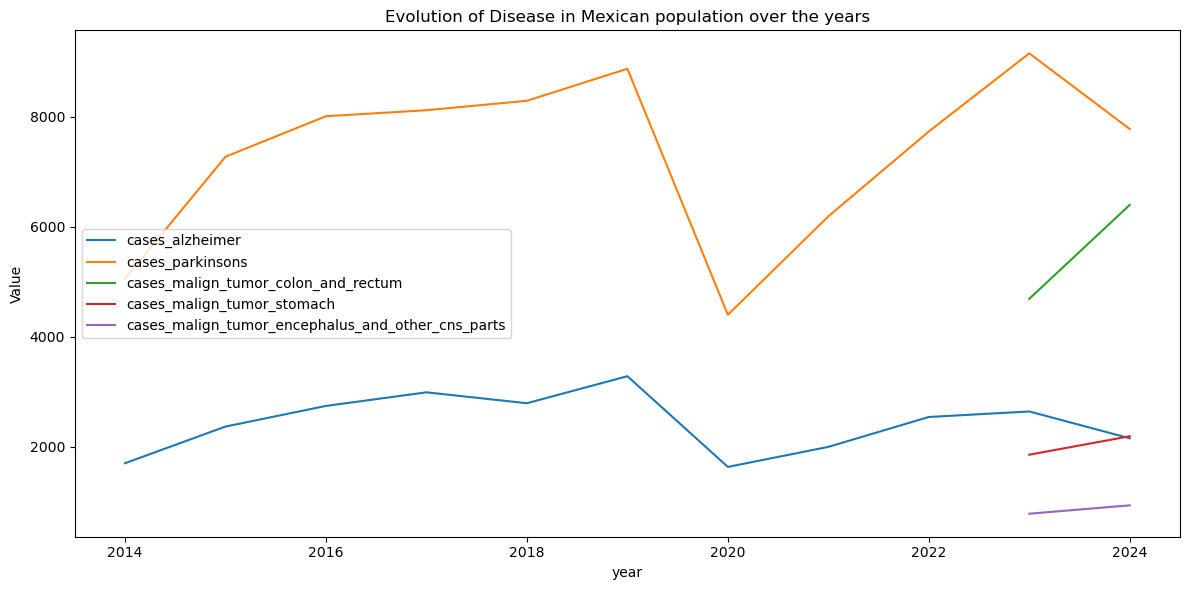

In [7]:
# 3. Add remaining labels and layout adjustments
ax.set_ylabel("Value")
ax.legend()
plt.tight_layout()
plt.show()

plot_columns_times_high = [
]

plot_columns_times_low = [ #0 to 800 cases

 'cases_alzheimer',
 'cases_parkinsons',
'cases_malign_tumor_colon_and_rectum',
 'cases_malign_tumor_stomach',
 'cases_malign_tumor_encephalus_and_other_cns_parts'
]


# 2. Plot the data using the DataFrame's plot method
# 'year' is set as the index, or x='year'
ax = d.set_index('year')[plot_columns_times_low].plot(
    figsize=(12, 6),
    title="Evolution of Disease in Mexican population over the years"
)

# 3. Add remaining labels and layout adjustments
ax.set_ylabel("Value")
ax.legend()
plt.tight_layout()
plt.show()


##### 1.1.1.1 All graphs combined

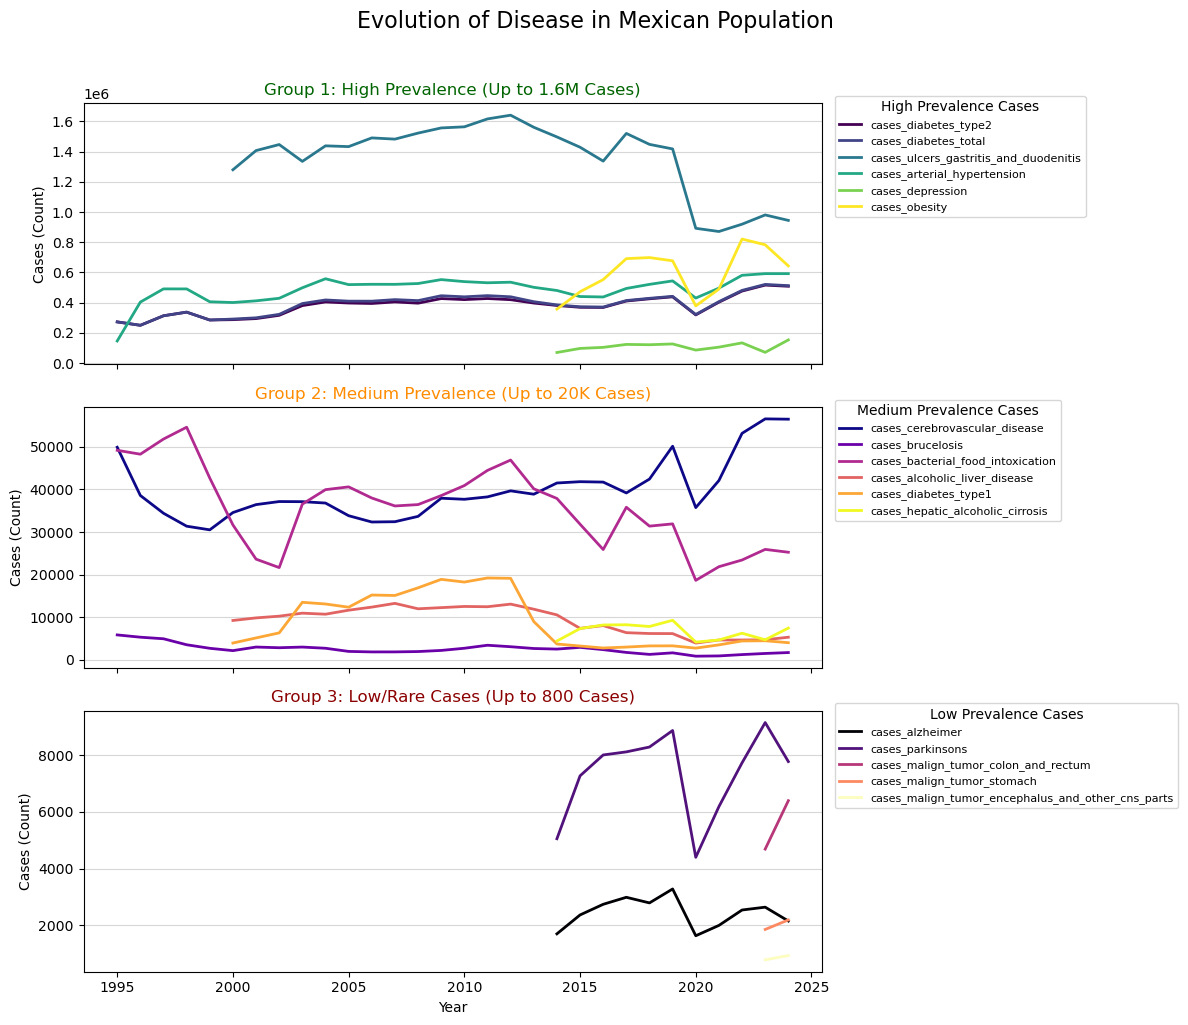

In [118]:
import matplotlib.pyplot as plt
import pandas as pd


# --- 1. Defining Groups ---

# Group 1: High Prevalence (0 to 1.6M)
plot_columns_high = [
    'cases_diabetes_type2',
    'cases_diabetes_total',
    'cases_ulcers_gastritis_and_duodenitis',
    'cases_arterial_hypertension',
    'cases_depression',
    'cases_obesity',
]

# Group 2: Medium/Lower Prevalence (0 to 20k)
plot_columns_medium = [
    'cases_cerebrovascular_disease',
    'cases_brucelosis',
    'cases_bacterial_food_intoxication',
    'cases_alcoholic_liver_disease',
    'cases_diabetes_type1',
    'cases_hepatic_alcoholic_cirrosis',
]

# Group 3: Very Low/Rare Cases (0 to 800)
plot_columns_low = [
    'cases_alzheimer',
    'cases_parkinsons',
    'cases_malign_tumor_colon_and_rectum',
    'cases_malign_tumor_stomach',
    'cases_malign_tumor_encephalus_and_other_cns_parts'
]

# --- 2. Creating the Figure with 3 Subplots ---
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(12, 10),  # Adjust size for 3 stacked plots
    sharex=True  # Makes sure all plots use the same year scale --> FALSE LOOKS BETtER IMO
)
# Set the main title for the entire figure
fig.suptitle("Evolution of Disease in Mexican Population", fontsize=16, y=1.02)
d_indexed = d.set_index('year')

# --- 3. Plotting Group 1: High Prevalence ---
d_indexed[plot_columns_high].plot(
    ax=axes[0],
    legend=False, # We use the explicit method below
    linewidth=2,
    cmap='viridis'
)
axes[0].set_title("Group 1: High Prevalence (Up to 1.6M Cases)", fontsize=12, color='darkgreen')
axes[0].set_ylabel("Cases (Count)")
axes[0].grid(axis='y', alpha=0.5)

# --- NEW LEGEND PLACEMENT for Group 1 ---
axes[0].legend(
    loc='upper left',              # Starting point for the anchor
    bbox_to_anchor=(1.01, 1.05),   # Moves the legend outside the plot area
    fontsize=8,
    frameon=True,                  # Keeps the legend box visible
    title="High Prevalence Cases"
)


# --- 4. Plotting Group 2: Medium Prevalence ---
d_indexed[plot_columns_medium].plot(
    ax=axes[1],
    legend=False, # We use the explicit method below
    linewidth=2,
    cmap='plasma'
)
axes[1].set_title("Group 2: Medium Prevalence (Up to 20K Cases)", fontsize=12, color='darkorange')
axes[1].set_ylabel("Cases (Count)")
axes[1].grid(axis='y', alpha=0.5)

# --- NEW LEGEND PLACEMENT for Group 2 ---
axes[1].legend(
    loc='upper left',
    bbox_to_anchor=(1.01, 1.05),
    fontsize=8,
    frameon=True,
    title="Medium Prevalence Cases"
)


# --- 5. Plotting Group 3: Low Prevalence ---
d_indexed[plot_columns_low].plot(
    ax=axes[2],
    legend=False, # We use the explicit method below
    linewidth=2,
    cmap='magma'
)
axes[2].set_title("Group 3: Low/Rare Cases (Up to 800 Cases)", fontsize=12, color='darkred')
axes[2].set_ylabel("Cases (Count)")
axes[2].set_xlabel("Year")
axes[2].grid(axis='y', alpha=0.5)

# --- NEW LEGEND PLACEMENT for Group 3 ---
axes[2].legend(
    loc='upper left',
    bbox_to_anchor=(1.01, 1.05),
    fontsize=8,
    frameon=True,
    title="Low Prevalence Cases"
)


# --- 6. Final Layout Adjustment ---
# Use constrained_layout instead of tight_layout with legends outside
plt.tight_layout()
plt.show()

## 1.1.2 GRAPH NOVA.CSV DATASET (NOVA FOODS)

In [28]:
list(n.columns.values)

['year',
 'total_kcal',
 'pct_kcal_unprocessed',
 'pct_kcal_ingredients',
 'pct_kcal_processed',
 'pct_kcal_ultra_processed']

#### GRAPH NOVA.CSV DATASET (NOVA FOODS)

NameError: name 'n' is not defined

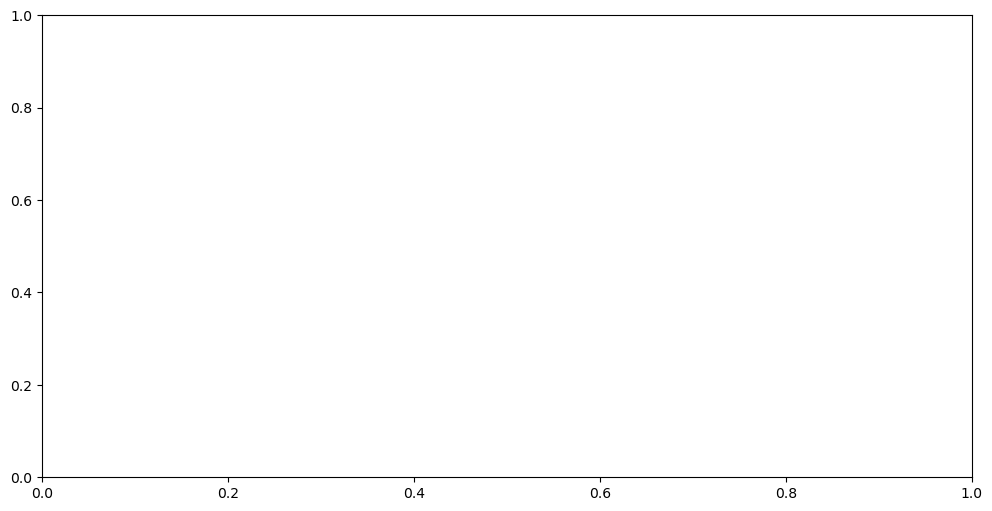

In [1]:
import matplotlib.pyplot as plt

# 1. Define the columns
pct_cols = ['pct_kcal_unprocessed', 'pct_kcal_ingredients', 'pct_kcal_processed', 'pct_kcal_ultra_processed']
total_col = 'total_kcal'

# 2. Create the figure and the first axis (for percentages)
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot percentages on the left axis (ax1)
n.set_index('year')[pct_cols].plot(ax=ax1)
ax1.set_ylabel("Percentage (%)")
ax1.set_ylim(0, 100) # Optional: lock percentages to 100

# 3. Create the second axis for Total Kcal
ax2 = ax1.twinx()
n.set_index('year')[total_col].plot(ax=ax2, color='black', linestyle='--', linewidth=2)
ax2.set_ylabel("Total Kilocalories (kcal)")

# 4. Final touches
plt.title("Consumption of unprocessed foods, ingredients, processed foods, ultraprocessed foods and total calories over the years")
ax1.legend(loc='center left')
ax2.legend(loc='center right')
plt.tight_layout()
plt.show()

# BLOQUE 2: DISEASES + Ultraprocessed foods - MERGING DATASETS


## 2.1 LOADING DATASETS & CLEANING DATASETS

In [31]:
## LOADING DATASETS & CLEANING DATASETS

### LOADING ###----------###----------###----------###----------###----------###----------###----------###----------###----------###----------###----------
#conda install matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#loading datasets
d = pd.read_csv('diseases.csv',decimal='.')
n = pd.read_csv('nova_food.csv',decimal='.')
#print(d.head())
#print("NOVA TABLE: ######### " , n.head())



### CLEANING AND UNIFYING FORMAT###----------###----------###----------###----------###----------###----------###----------###----------###----------###----------###----------

import re

# Standardize column names
d.columns = d.columns.str.strip().str.lower().str.replace(" ", "_")
n.columns = n.columns.str.strip().str.lower().str.replace(" ", "_")

# Convert everything except "year" to numeric in DISEASES dataset
for col in d.columns:
    if col != "year" and col != "cases_source":
        d[col] = (
            d[col]
            .astype(str)
            .str.replace(",", "", regex=False)   # remove commas
            .str.replace(" ", "", regex=False)   # remove spaces in numbers
            .str.replace("\u202f", "", regex=False)   # remove narrow non-break space
            .str.replace("\xa0", "", regex=False)     # remove no-break space
        )
        d[col] = pd.to_numeric(d[col], errors="coerce")
        
#Explicitly ensure 'cases_source' is a string ---
d["cases_source"] = d["cases_source"].astype(str)

# Convert everything except "year" to numeric in NOVA FOODS dataset
for col in n.columns:
    if col != "year":
        n[col] = (
            n[col]
            .astype(str)
            .str.replace(",", "", regex=False)   # remove commas
            .str.replace(" ", "", regex=False)   # remove spaces in numbers
            .str.replace("\u202f", "", regex=False)   # remove narrow non-break space
            .str.replace("\xa0", "", regex=False)     # remove no-break space
        )
        # Convert to numeric
        n[col] = pd.to_numeric(n[col], errors="coerce")


#Check DISEASES dataset:
print("\n###----------###----------###----------###\nDISEASE DATASET\n###----------###----------###----------###")
print(d.info())
print(d.head())

print("\n###----------###----------###----------###----------###----------###----------###----------###----------###----------###----------###----------\n")
print("\n###----------###----------###----------###----------###----------###----------###----------###----------###----------###----------###----------\n")
      
#Check NOVA dataset:
print("\n###----------###----------###----------###\nNOVA FOODS DATASET\n###----------###----------###----------###")
print(n.info())
print(n.head())


###----------###----------###----------###
DISEASE DATASET
###----------###----------###----------###
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 21 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   year                                               30 non-null     int64  
 1   cases_diabetes_type1                               25 non-null     float64
 2   cases_diabetes_type2                               30 non-null     float64
 3   cases_diabetes_total                               30 non-null     float64
 4   cases_depression                                   11 non-null     float64
 5   cases_alzheimer                                    11 non-null     float64
 6   cases_parkinsons                                   11 non-null     float64
 7   cases_obesity                                      11 non-null     fl

## BLOQUE 2.2 MERGING DATASETS

In [144]:
#Now I can merge datasets
#strict inner join on year
merged = pd.merge(d, n, on="year", how="inner")

print("Merged shape:", merged.shape)


# Save merged dataset
merged.to_csv("merged_ecological_dataset.csv", index=False)
print("Merged dataset saved as 'merged_ecological_dataset.csv'")

#loading merged dataset
merged = pd.read_csv('merged_ecological_dataset.csv',decimal='.')
merged

Merged shape: (11, 26)
Merged dataset saved as 'merged_ecological_dataset.csv'


,year,cases_diabetes_type1,cases_diabetes_type2,cases_diabetes_total,cases_depression,cases_alzheimer,cases_parkinsons,cases_obesity,cases_malign_tumor_colon_and_rectum,cases_malign_tumor_stomach,...,cases_arterial_hypertension,cases_alcoholic_liver_disease,total_reported_cases,population_year,cases_source,total_kcal,pct_kcal_unprocessed,pct_kcal_ingredients,pct_kcal_processed,pct_kcal_ultra_processed
0,2016,2789.0,368069.0,370858.0,103636.0,2746.0,8009.0,552512.0,NaN,NaN,...,437439.0,8052.0,41773495.0,123587407,https://epidemiologia.salud.gob.mx/anuario/201...,1875.4,61.4,9.0,6.5,23.1
1,2014,3728.0,381099.0,384827.0,69594.0,1705.0,5057.0,356712.0,NaN,NaN,...,480332.0,10560.0,46195653.0,121048604,https://epidemiologia.salud.gob.mx/anuario/201...,1890.9,62.3,9.3,6.1,22.3
2,2012,19141.0,419493.0,438634.0,NaN,NaN,NaN,NaN,NaN,NaN,...,535196.0,13086.0,44330320.0,118060514,https://epidemiologia.salud.gob.mx/anuario/201...,1899.3,60.9,9.1,6.2,23.7
3,2010,18261.0,420032.0,438293.0,NaN,NaN,NaN,NaN,NaN,NaN,...,539078.0,12537.0,45080477.0,114756059,https://epidemiologia.salud.gob.mx/anuario/201...,1900.0,62.3,10.0,6.0,21.7
4,2008,16909.0,396374.0,413283.0,NaN,NaN,NaN,NaN,NaN,NaN,...,526484.0,11990.0,40013071.0,111275915,https://epidemiologia.salud.gob.mx/anuario/200...,1920.8,62.7,10.0,6.0,21.4
5,2006,15220.0,394360.0,409580.0,NaN,NaN,NaN,NaN,NaN,NaN,...,521486.0,12383.0,39789594.0,107885646,https://epidemiologia.salud.gob.mx/anuario/200...,1841.9,61.6,10.1,6.0,22.3
6,2004,13116.0,404562.0,417678.0,NaN,NaN,NaN,NaN,NaN,NaN,...,558139.0,10718.0,42594791.0,104970581,https://epidemiologia.salud.gob.mx/anuario/200...,1692.9,67.1,7.9,5.4,19.5
7,2002,6337.0,315948.0,322285.0,NaN,NaN,NaN,NaN,NaN,NaN,...,428730.0,10260.0,47055196.0,102167274,https://epidemiologia.salud.gob.mx/anuario/200...,2111.4,65.4,11.9,5.5,17.2
8,2000,3955.0,287180.0,291135.0,NaN,NaN,NaN,NaN,NaN,NaN,...,400693.0,9248.0,46326006.0,99368858,https://epidemiologia.salud.gob.mx/anuario/200...,2199.5,65.2,13.3,5.2,16.3
9,1998,NaN,336967.0,336967.0,NaN,NaN,NaN,NaN,NaN,NaN,...,490850.0,NaN,38616769.0,96799183,https://epidemiologia.salud.gob.mx/anuario/199...,2076.6,66.8,12.1,5.3,15.8


## Bloque 2.3 NOVA FOODS TO DISEASES SIMPLE CORRELATIONS

In [33]:
## NOVA FOODS TO DISEASES CORRELATIONS
import pandas as pd
import numpy as np

#loading merged dataset
merged = pd.read_csv('merged_ecological_dataset.csv',decimal='.')
merged

# 1. Automatically detect numeric columns
numeric_cols = merged.select_dtypes(include=[np.number]).columns.tolist()

print(f"Detected {len(numeric_cols)} numeric columns:")
print(numeric_cols)

# 2. Pearson correlation
pearson_corr = merged[numeric_cols].corr(method='pearson')
pearson_corr.to_csv("pearson_correlations.csv")
print("\nPearson correlation matrix saved as 'pearson_correlations.csv'")

# 3. Spearman correlation
spearman_corr = merged[numeric_cols].corr(method='spearman')
spearman_corr.to_csv("spearman_correlations.csv")
print("Spearman correlation matrix saved as 'spearman_correlations.csv'")

# 4. Extract important columns automatically
#NOTE: This code automatically finds the correct column names, even if the dataset uses different naming styles.
def find_col(keyword_list):
    for col in numeric_cols:
        if any(k.lower() in col.lower() for k in keyword_list):
            return col
    return None

col_ultra = find_col(["ultra", "nova4", "ultra_processed"])
col_diabetes = find_col(["diabetes"])
col_obesity = find_col(["obesity"])

print("\nKey detected variables:")
print("NOVA4 / Ultra-processed:", col_ultra)
print("Diabetes:", col_diabetes)
print("Obesity:", col_obesity)

# 5. Extract correlations of interest
correlations_of_interest = {}

for key, col in [("NOVA4_ultra_processed", col_ultra),
                 ("Diabetes", col_diabetes),
                 ("Obesity", col_obesity)]:
    
    if col is None:
        correlations_of_interest[key] = "NOT FOUND"
        continue
    
    correlations_of_interest[key] = pearson_corr[col].sort_values(ascending=False)

# Save the extracted correlations
for key in correlations_of_interest:
    if isinstance(correlations_of_interest[key], pd.Series):
        correlations_of_interest[key].to_csv(f"correlations_{key}.csv")
        print(f"Saved correlations for {key} as 'correlations_{key}.csv'")

# 6. Print correlation summaries
print("\n=== Correlation summary ===")
for key, value in correlations_of_interest.items():
    print(f"\n--- {key} ---")
    print(value)


Detected 25 numeric columns:
['year', 'cases_diabetes_type1', 'cases_diabetes_type2', 'cases_diabetes_total', 'cases_depression', 'cases_alzheimer', 'cases_parkinsons', 'cases_obesity', 'cases_malign_tumor_colon_and_rectum', 'cases_malign_tumor_stomach', 'cases_malign_tumor_encephalus_and_other_cns_parts', 'cases_cerebrovascular_disease', 'cases_bacterial_food_intoxication', 'cases_brucelosis', 'cases_ulcers_gastritis_and_duodenitis', 'cases_hepatic_alcoholic_cirrosis', 'cases_arterial_hypertension', 'cases_alcoholic_liver_disease', 'total_reported_cases', 'population_year', 'total_kcal', 'pct_kcal_unprocessed', 'pct_kcal_ingredients', 'pct_kcal_processed', 'pct_kcal_ultra_processed']

Pearson correlation matrix saved as 'pearson_correlations.csv'
Spearman correlation matrix saved as 'spearman_correlations.csv'

Key detected variables:
NOVA4 / Ultra-processed: pct_kcal_ultra_processed
Diabetes: cases_diabetes_type1
Obesity: cases_obesity
Saved correlations for NOVA4_ultra_processed as 

## Bloque 2.3.1 Restrict correlations only to columns with ≥ 5 datapoints


In [34]:
# Count non-null values for each numeric column
valid_counts = merged[numeric_cols].count()

# Keep only variables with at least MIN datapoints
MIN_POINTS = 5
valid_cols = valid_counts[valid_counts >= MIN_POINTS].index.tolist()

print(f"Variables kept for correlation (≥{MIN_POINTS} datapoints):")
print(valid_cols)
print("#########################################\n\n####################################\n\n####################################")

# Remove non-health outcome variables from correlation matrix
cols_to_exclude = ["year", "population_year", "total_reported_cases"]

filtered_cols = [col for col in valid_cols if col not in cols_to_exclude]

print("Columns used for valid ecological correlations:")
print(filtered_cols)

Variables kept for correlation (≥5 datapoints):
['year', 'cases_diabetes_type1', 'cases_diabetes_type2', 'cases_diabetes_total', 'cases_cerebrovascular_disease', 'cases_bacterial_food_intoxication', 'cases_brucelosis', 'cases_ulcers_gastritis_and_duodenitis', 'cases_arterial_hypertension', 'cases_alcoholic_liver_disease', 'total_reported_cases', 'population_year', 'total_kcal', 'pct_kcal_unprocessed', 'pct_kcal_ingredients', 'pct_kcal_processed', 'pct_kcal_ultra_processed']
#########################################

####################################

####################################
Columns used for valid ecological correlations:
['cases_diabetes_type1', 'cases_diabetes_type2', 'cases_diabetes_total', 'cases_cerebrovascular_disease', 'cases_bacterial_food_intoxication', 'cases_brucelosis', 'cases_ulcers_gastritis_and_duodenitis', 'cases_arterial_hypertension', 'cases_alcoholic_liver_disease', 'total_kcal', 'pct_kcal_unprocessed', 'pct_kcal_ingredients', 'pct_kcal_processed', 'pc

### Bloque 2.3.2 Saving Corrected Simple correlation Matrix

In [35]:
pearson_merged = merged[filtered_cols].corr(method='pearson')
spearman_merged = merged[filtered_cols].corr(method='spearman')

pearson_merged.to_csv("pearson_merged_pear_corr.csv")
spearman_merged.to_csv("spearman_merged_spear_corr.csv")

print("Saved final correlation matrices.")

print(pearson_merged)
print("#########################################\n\n####################################\n\n#############################################################################\n\n####################################\n\n#######################################################################################################################################################################\n\n#########################################\n\n####################################\n\n####################################")

print(spearman_merged)

Saved final correlation matrices.
                                       cases_diabetes_type1  \
cases_diabetes_type1                               1.000000   
cases_diabetes_type2                               0.746492   
cases_diabetes_total                               0.802089   
cases_cerebrovascular_disease                     -0.378743   
cases_bacterial_food_intoxication                  0.731556   
cases_brucelosis                                   0.103047   
cases_ulcers_gastritis_and_duodenitis              0.793296   
cases_arterial_hypertension                        0.851839   
cases_alcoholic_liver_disease                      0.912582   
total_kcal                                        -0.423493   
pct_kcal_unprocessed                              -0.254908   
pct_kcal_ingredients                              -0.341979   
pct_kcal_processed                                 0.155532   
pct_kcal_ultra_processed                           0.396019   

                    

### Bloque 2.3.3 1.- PEARSON & SPEARMAN CORRELATIONS HEATMAP

### PEARSON HEATMAP USING CASES


# PEARSON CORRELATION MATRIX
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(14, 12))
plt.imshow(pearson_merged, interpolation='nearest')
plt.title("Pearson Correlation Matrix")
plt.xticks(range(len(pearson_merged.columns)), pearson_merged.columns, rotation=90)
plt.yticks(range(len(pearson_merged.index)), pearson_merged.index)

# Loop over the data and place text annotations
for i in range(len(pearson_merged.index)):
    for j in range(len(pearson_merged.columns)):
        # Get the value from the DataFrame and format it to two decimal places
        value = pearson_merged.iloc[i, j]
        
        # Determine text color based on the cell's value for better visibility
        # The threshold (0.5) might need adjustment depending on your color map
        text_color = "black" if abs(value) < 0.5 else "white" 
        
        # Add the text annotation to the plot
        plt.text(j, i, f"{value:.2f}",
                 ha="center", va="center", color=text_color, fontsize=10)



plt.colorbar()
plt.tight_layout()
plt.show()

in this block of correcting correlations for the merged dataset, I would only like to do the same process for cases_diabetes_total (because before many years mexico measuerd the 2 tyes into 1 category), also ultraprocessed vs cases_ulcers_gastritis..., cases_arterial_hypertension and that is it. Would it be correct to use the same procedure for these? later I will do the same test for ultraprocessed foods vs unprocessed in the original dataset NOVA, and finally I would like to correlate most diseases to diabetes type 2 in the original dataset of Diseases where I have many many datapoints what do you suggest for these last 2?

### SPEARMAN CORRELATIONS HEATMAP


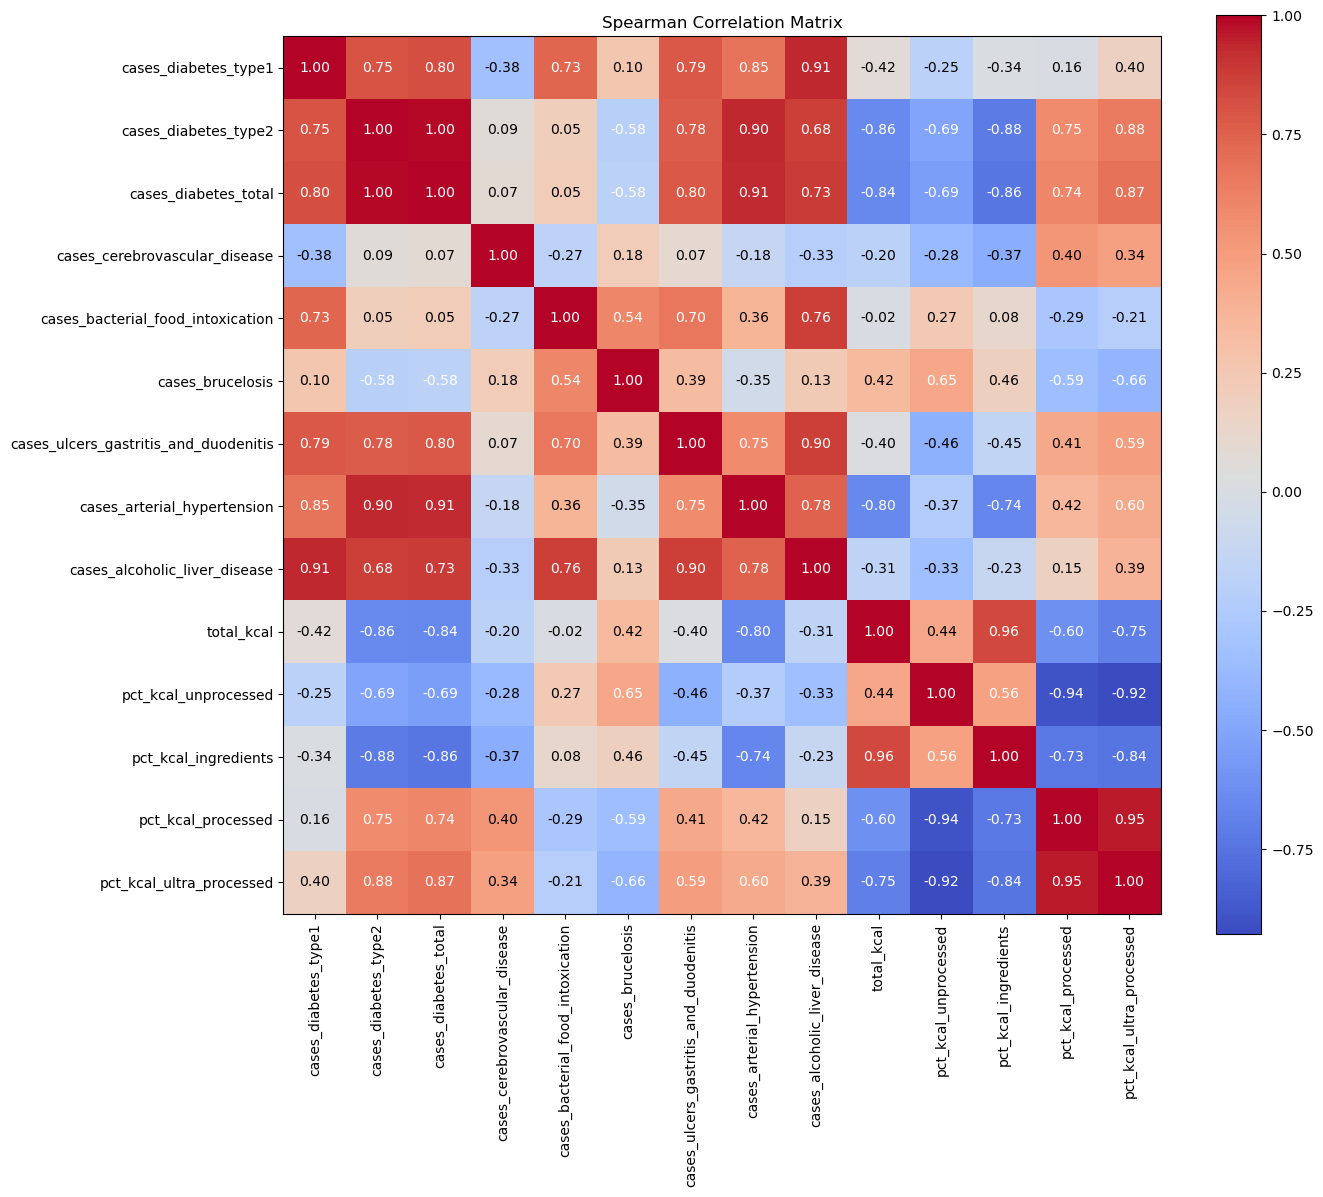

In [38]:
plt.figure(figsize=(14, 12))
plt.imshow(spearman_merged, interpolation='nearest', cmap='coolwarm')
plt.title("Spearman Correlation Matrix")
plt.xticks(range(len(spearman_merged.columns)), spearman_merged.columns, rotation=90)
plt.yticks(range(len(spearman_merged.index)), spearman_merged.index)

# Loop over the data and place text annotations
for i in range(len(pearson_merged.index)):
    for j in range(len(pearson_merged.columns)):
        # Get the value from the DataFrame and format it to two decimal places
        value = pearson_merged.iloc[i, j]
        
        # Determine text color based on the cell's value for better visibility
        # The threshold (0.5) might need adjustment depending on your color map
        text_color = "black" if abs(value) < 0.5 else "white" 
        
        # Add the text annotation to the plot
        plt.text(j, i, f"{value:.2f}",
                 ha="center", va="center", color=text_color, fontsize=10)


plt.colorbar()
plt.tight_layout()
plt.show()


                                 Disease         R   p_value
0  cases_ulcers_gastritis_and_duodenitis  0.591484  0.093421
1            cases_arterial_hypertension  0.604076  0.049040
2          cases_cerebrovascular_disease  0.338718  0.308234
3          cases_alcoholic_liver_disease  0.391440  0.297496


/var/folders/w9/bwws86216wgb0hvxvlbzqqt40000gn/T/ipykernel_94990/521280394.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="R", y="Disease", palette="viridis")


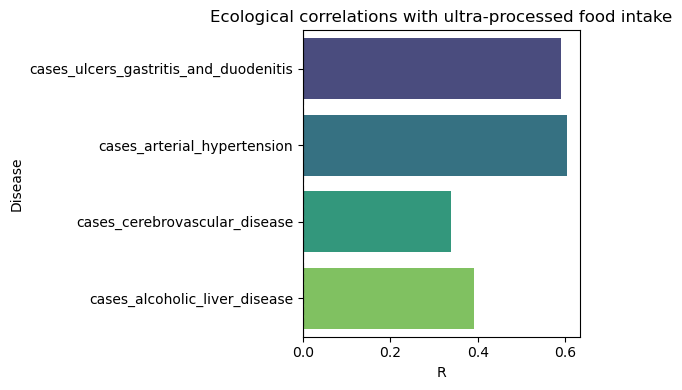

Simple linear regression and correlation analyses yielded identical results, as expected for bivariate models.


In [125]:
# Correlaciones ecológicas corregidas (NO time series)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# Load merged ecological dataset
df = pd.read_csv("merged_ecological_dataset.csv")

# Diseases to explore ecologically
diseases = [
    "cases_ulcers_gastritis_and_duodenitis",
    "cases_arterial_hypertension",
    "cases_cerebrovascular_disease",
    "cases_alcoholic_liver_disease"
]

x = df["pct_kcal_ultra_processed"]

results = []

for d in diseases:
    y = df[d]
    mask = x.notna() & y.notna()
    r, p = pearsonr(x[mask], y[mask])
    results.append([d, r, p])

results_df = pd.DataFrame(results, columns=["Disease", "R", "p_value"])
print(results_df)

# VISUALIZATION
plt.figure(figsize=(6,4))
sns.barplot(data=results_df, x="R", y="Disease", palette="viridis")
plt.axvline(0, color="black", linestyle="--")
plt.title("Ecological correlations with ultra-processed food intake")
plt.tight_layout()
plt.show()

print("Simple linear regression and correlation analyses yielded identical results, as expected for bivariate models.")


### BLOQUE 3 - EXPLORING MERGED DATASETS: Exploratory graphs + Key Scatterplots + RAW Linear Regresions

#### b_3.1.A UPF vs Diabetes vs CVD across years - exploratory graph

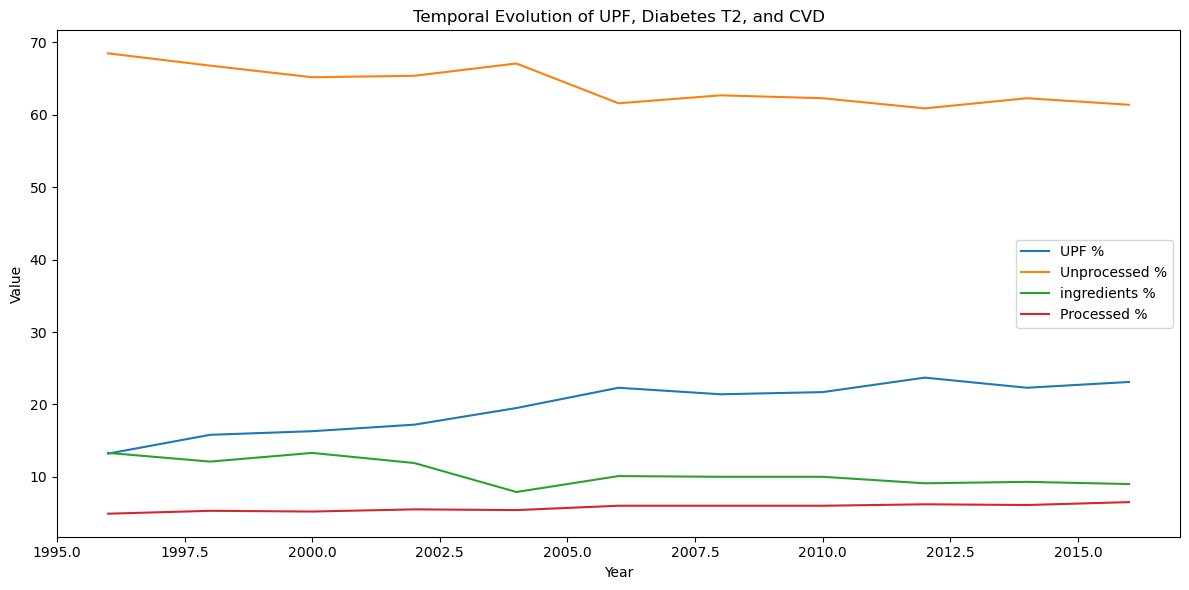

In [39]:
plt.figure(figsize=(12, 6))
plt.plot(merged["year"], merged["pct_kcal_ultra_processed"], label="UPF %")
plt.plot(merged["year"], merged["pct_kcal_unprocessed"], label="Unprocessed %")
plt.plot(merged["year"], merged["pct_kcal_ingredients"], label="ingredients %")
plt.plot(merged["year"], merged["pct_kcal_processed"], label="Processed %")
#plt.plot(merged["year"], merged["total_kcal"], label="total kcal %")
#plt.plot(merged["year"], merged["cases_diabetes_type2"], label="Diabetes Type 2")
#plt.plot(merged["year"], merged["cases_cvd"], label="CVD")

plt.xlabel("Year")
plt.ylabel("Value")
plt.legend()
plt.title("Temporal Evolution of UPF, Diabetes T2, and CVD")
plt.tight_layout()
plt.show()


## b_3.1.B- cases_diabetes_type2 VS pct_kcal_ultra_processed: Linear Regresions

    pct_kcal_ultra_processed  cases_diabetes_type2
0                       23.1              368069.0
1                       22.3              381099.0
2                       23.7              419493.0
3                       21.7              420032.0
4                       21.4              396374.0
5                       22.3              394360.0
6                       19.5              404562.0
7                       17.2              315948.0
8                       16.3              287180.0
9                       15.8              336967.0
10                      13.2              249774.0


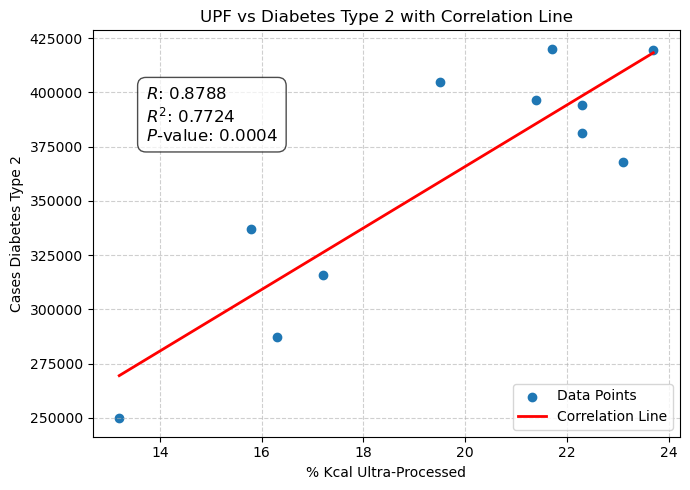

In [42]:
#### A.- cases_diabetes_type2 VS pct_kcal_ultra_processed: Linear Regresions
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

# -------------------------------------#-------------------------------------
#print(merged.dtypes)
merged_clean = merged.dropna(subset=["pct_kcal_ultra_processed", "cases_diabetes_type2"])

## Checking for missing values
print(merged[["pct_kcal_ultra_processed","cases_diabetes_type2"]])

##
x = merged_clean["pct_kcal_ultra_processed"]
y = merged_clean["cases_diabetes_type2"]
# -------------------------------------#-------------------------------------

# 1. Calculate Linear Regression
slope, intercept, r_value, p_value, std_err = linregress(x, y)

# Calculate R-squared and round values for display
r_squared = r_value**2
r_value_rounded = round(r_value, 4)
r_squared_rounded = round(r_squared, 4)
p_value_rounded = round(p_value, 4)


# ---
# 2. Generate the regression line data
# Create two points for the line based on the min/max of the X data
x_fit = np.array([x.min(), x.max()])
y_fit = slope * x_fit + intercept

# ---
# 3. Create the plot
plt.figure(figsize=(7, 5))

# Scatter Plot (Your original code)
plt.scatter(x, y, label='Data Points')

# Regression Line (New addition)
plt.plot(x_fit, y_fit, color='red', linestyle='-', linewidth=2, label='Correlation Line')

# Labels and Title
plt.xlabel("% Kcal Ultra-Processed")
plt.ylabel("Cases Diabetes Type 2")
plt.title("UPF vs Diabetes Type 2 with Correlation Line")

# ---
# 4. Add the R and R-squared values as text annotation (New addition)
text_to_display = (
    f'$R$: {r_value_rounded}\n'
    f'$R^2$: {r_squared_rounded}\n'
    f'$P$-value: {p_value_rounded}' # Añadido el valor P
)

# Calculate position for the text (e.g., top-left corner)
x_min, x_max = x.min(), x.max()
y_min, y_max = y.min(), y.max()
x_pos = x_min + 0.05 * (x_max - x_min)
y_pos = y_max - 0.10 * (y_max - y_min)

plt.text(x_pos, y_pos, text_to_display, 
         fontsize=12, 
         verticalalignment='top',
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='black', boxstyle='round,pad=0.5'))

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()


INTERPRETATION OF A.- UPF vs Diabetes vs CVD across years

-- Meaning of R2=0.772. This means that approximately 77.2% of the variability observed in the cases of Type 2 Diabetes can be explained by the variability in the consumption of ultra-processed foods. The remaining ∼22.8% is likely due to other factors (e.g., genetics, physical activity levels, age, total caloric intake, or random chance).

-- R=0.878838 means that as the percentage of calories from ultra-processed food (X) increases, the number of Type 2 Diabetes cases (Y) also tends to increase significantly.

# b_3.1.C.- Cerebrovascular Disease vs pct_kcal_ultra_processed: Linear Regresions

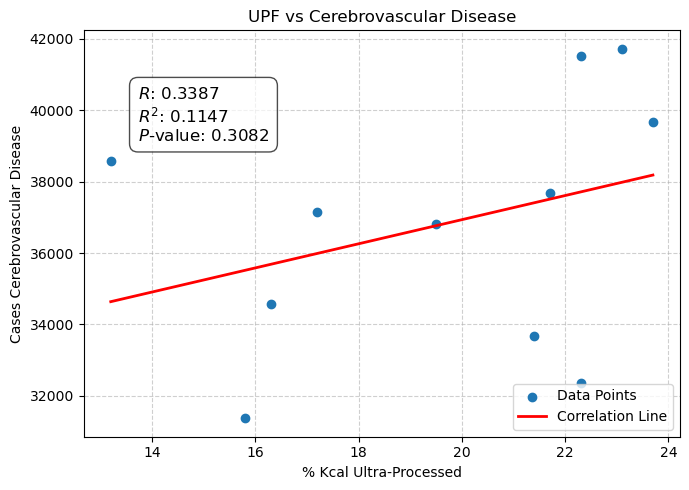

In [165]:

#### B.- Cerebrovascular Disease vs pct_kcal_ultra_processed: Linear Regresions

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

# Assuming your 'merged' DataFrame is ready and imported

# ---
# 1. Calculate Linear Regression
x = merged["pct_kcal_ultra_processed"]
y = merged["cases_cerebrovascular_disease"]

slope, intercept, r_value, p_value, std_err = linregress(x, y)

# Calculate R-squared and round values for display
r_squared = r_value**2
r_value_rounded = round(r_value, 4)
r_squared_rounded = round(r_squared, 4)
p_value_rounded = round(p_value, 4)

# ---
# 2. Generate the regression line data
# Create two points for the line based on the min/max of the X data
x_fit = np.array([x.min(), x.max()])
y_fit = slope * x_fit + intercept

# ---
# 3. Create the plot
plt.figure(figsize=(7, 5))

# Scatter Plot (Your original code)
plt.scatter(x, y, label='Data Points')

# Regression Line (New addition)
plt.plot(x_fit, y_fit, color='red', linestyle='-', linewidth=2, label='Correlation Line')

# Labels and Title
plt.xlabel("% Kcal Ultra-Processed")
plt.ylabel("Cases Cerebrovascular Disease")
plt.title("UPF vs Cerebrovascular Disease")

# ---
# 4. Add the R and R-squared values as text annotation (New addition)
text_to_display = (
    f'$R$: {r_value_rounded}\n'
    f'$R^2$: {r_squared_rounded}\n'
    f'$P$-value: {p_value_rounded}' # Añadido el valor P
)

# Calculate position for the text (e.g., top-left corner)
x_min, x_max = x.min(), x.max()
y_min, y_max = y.min(), y.max()
x_pos = x_min + 0.05 * (x_max - x_min)
y_pos = y_max - 0.10 * (y_max - y_min)

plt.text(x_pos, y_pos, text_to_display, 
         fontsize=12, 
         verticalalignment='top',
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='black', boxstyle='round,pad=0.5'))

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()


####  b_3.1.D .- alcoholic liver disease vs pct_kcal_ultra_processed: Linear Regresions

    pct_kcal_ultra_processed  cases_alcoholic_liver_disease
0                       23.1                         8052.0
1                       22.3                        10560.0
2                       23.7                        13086.0
3                       21.7                        12537.0
4                       21.4                        11990.0
5                       22.3                        12383.0
6                       19.5                        10718.0
7                       17.2                        10260.0
8                       16.3                         9248.0
9                       15.8                            NaN
10                      13.2                            NaN


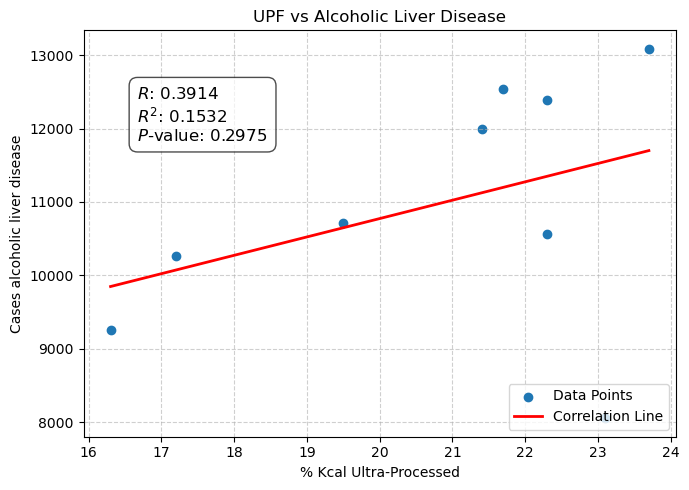

In [43]:
### C.- alcoholic liver disease vs pct_kcal_ultra_processed: Linear Regresions
# ---

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

## TROUBLE-SHOOTING ---------------------------------------------------------------------------------------------------------
#print(merged.dtypes)
merged_clean = merged.dropna(subset=["pct_kcal_ultra_processed", "cases_alcoholic_liver_disease"])

## Checking for missing values
print(merged[["pct_kcal_ultra_processed","cases_alcoholic_liver_disease"]])

##
x = merged_clean["pct_kcal_ultra_processed"]
y = merged_clean["cases_alcoholic_liver_disease"]

## ---------------------------------------------------------------------------------------------------------------------------

slope, intercept, r_value, p_value, std_err = linregress(x, y)

# Calculate R-squared and round values for display
r_squared = r_value**2
r_value_rounded = round(r_value, 4)
r_squared_rounded = round(r_squared, 4)
# Nuevo: Redondear el valor P
p_value_rounded = round(p_value, 4)

# ---
# 2. Generate the regression line data
# Create two points for the line based on the min/max of the X data
x_fit = np.array([x.min(), x.max()])
y_fit = slope * x_fit + intercept

# ---
# 3. Create the plot
plt.figure(figsize=(7, 5))

# Scatter Plot (Your original code)
plt.scatter(x, y, label='Data Points')

# Regression Line (New addition)
plt.plot(x_fit, y_fit, color='red', linestyle='-', linewidth=2, label='Correlation Line')

# Labels and Title
plt.xlabel("% Kcal Ultra-Processed")
plt.ylabel("Cases alcoholic liver disease")
plt.title("UPF vs Alcoholic Liver Disease")

# ---
# 4. Add the R and R-squared values as text annotation (New addition)
text_to_display = (
    f'$R$: {r_value_rounded}\n'
    f'$R^2$: {r_squared_rounded}\n'
    f'$P$-value: {p_value_rounded}' # Añadido el valor P
)

# Calculate position for the text (e.g., top-left corner)
x_min, x_max = x.min(), x.max()
y_min, y_max = y.min(), y.max()
x_pos = x_min + 0.05 * (x_max - x_min)
y_pos = y_max - 0.10 * (y_max - y_min)

plt.text(x_pos, y_pos, text_to_display, 
         fontsize=12, 
         verticalalignment='top',
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='black', boxstyle='round,pad=0.5'))

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()

###  b_3.1.E .- Ulcers-gastritis-duodenitis vs pct_kcal_ultra_processed: Linear Regresions

    pct_kcal_ultra_processed  cases_ulcers_gastritis_and_duodenitis
0                       23.1                              1337562.0
1                       22.3                              1497802.0
2                       23.7                              1641712.0
3                       21.7                              1564669.0
4                       21.4                              1523116.0
5                       22.3                              1491309.0
6                       19.5                              1438778.0
7                       17.2                              1447260.0
8                       16.3                              1280268.0
9                       15.8                                    NaN
10                      13.2                                    NaN


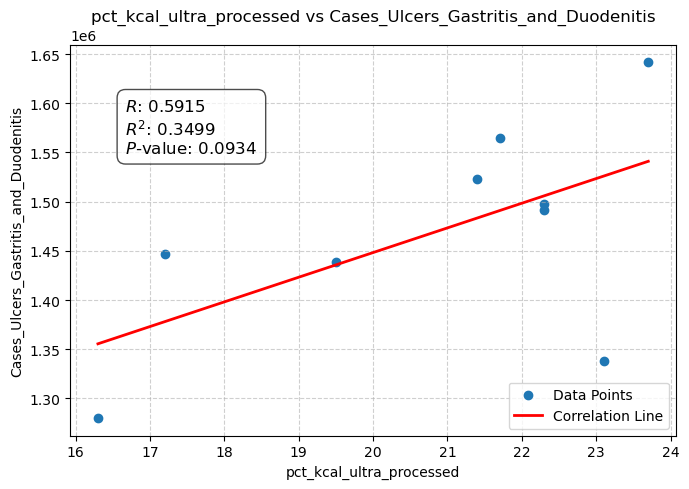

In [44]:
#cases_ulcers_gastritis_and_duodenitis

## TROUBLE-SHOOTING ---------------------------------------------------------------------------------------------------------

#print(merged.dtypes)
merged_clean = merged.dropna(subset=["pct_kcal_ultra_processed", "cases_ulcers_gastritis_and_duodenitis"])

## Checking for missing values
print(merged[["pct_kcal_ultra_processed","cases_ulcers_gastritis_and_duodenitis"]])

##
x = merged_clean["pct_kcal_ultra_processed"]
y = merged_clean["cases_ulcers_gastritis_and_duodenitis"]

## ---------------------------------------------------------------------------------------------------------------------------

slope, intercept, r_value, p_value, std_err = linregress(x, y)

# Calculate R-squared and round values for display
r_squared = r_value**2
r_value_rounded = round(r_value, 4)
r_squared_rounded = round(r_squared, 4)
p_value_rounded = round(p_value, 4)

# ---
# 2. Generate the regression line data 
# Create two points for the line based on the min/max of the X data
x_fit = np.array([x.min(), x.max()])
y_fit = slope * x_fit + intercept

# ---
# 3. Create the plot
plt.figure(figsize=(7, 5))

# Scatter Plot (Your original code)
plt.scatter(x, y, label='Data Points')

# Regression Line (New addition)
plt.plot(x_fit, y_fit, color='red', linestyle='-', linewidth=2, label='Correlation Line')

# Labels and Title
plt.xlabel("pct_kcal_ultra_processed")
plt.ylabel("Cases_Ulcers_Gastritis_and_Duodenitis")
plt.title("pct_kcal_ultra_processed vs Cases_Ulcers_Gastritis_and_Duodenitis")

# ---
# 4. Add the R and R-squared values as text annotation (New addition)
text_to_display = (
    f'$R$: {r_value_rounded}\n'
    f'$R^2$: {r_squared_rounded}\n'
    f'$P$-value: {p_value_rounded}' # Añadido el valor P
)

# Calculate position for the text (e.g., top-left corner)
x_min, x_max = x.min(), x.max()
y_min, y_max = y.min(), y.max()
x_pos = x_min + 0.05 * (x_max - x_min)
y_pos = y_max - 0.10 * (y_max - y_min)

plt.text(x_pos, y_pos, text_to_display, 
         fontsize=12, 
         verticalalignment='top',
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='black', boxstyle='round,pad=0.5'))

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()

####  b_3.1.F.- cases_arterial_hypertension vs pct_kcal_ultra_processed: Linear Regresions

    pct_kcal_ultra_processed  cases_arterial_hypertension
0                       23.1                     437439.0
1                       22.3                     480332.0
2                       23.7                     535196.0
3                       21.7                     539078.0
4                       21.4                     526484.0
5                       22.3                     521486.0
6                       19.5                     558139.0
7                       17.2                     428730.0
8                       16.3                     400693.0
9                       15.8                     490850.0
10                      13.2                     403582.0


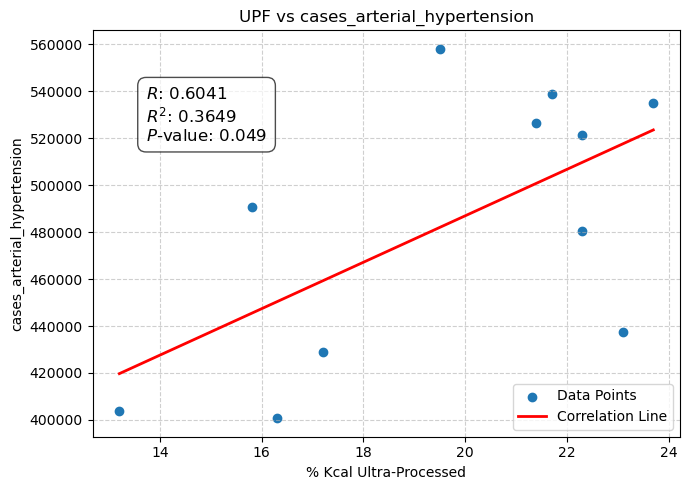

In [46]:
### E.- cases_arterial_hypertension vs pct_kcal_ultra_processed: Linear Regresions

## TROUBLE-SHOOTING ---------------------------------------------------------------------------------------------------------

#print(merged.dtypes)
merged_clean = merged.dropna(subset=["pct_kcal_ultra_processed", "cases_arterial_hypertension"])

## Checking for missing values
print(merged[["pct_kcal_ultra_processed","cases_arterial_hypertension"]])

##
x = merged_clean["pct_kcal_ultra_processed"]
y = merged_clean["cases_arterial_hypertension"]

## ---------------------------------------------------------------------------------------------------------------------------

slope, intercept, r_value, p_value, std_err = linregress(x, y)

# Calculate R-squared and round values for display
r_squared = r_value**2
r_value_rounded = round(r_value, 4)
r_squared_rounded = round(r_squared, 4)
p_value_rounded = round(p_value, 4)

# ---
# 2. Generate the regression line data
# Create two points for the line based on the min/max of the X data
x_fit = np.array([x.min(), x.max()])
y_fit = slope * x_fit + intercept

# ---
# 3. Create the plot
plt.figure(figsize=(7, 5))

# Scatter Plot (Your original code)
plt.scatter(x, y, label='Data Points')

# Regression Line (New addition)
plt.plot(x_fit, y_fit, color='red', linestyle='-', linewidth=2, label='Correlation Line')

# Labels and Title
plt.xlabel("% Kcal Ultra-Processed")
plt.ylabel("cases_arterial_hypertension")
plt.title("UPF vs cases_arterial_hypertension")

# ---
# 4. Add the R and R-squared values as text annotation (New addition)
text_to_display = (
    f'$R$: {r_value_rounded}\n'
    f'$R^2$: {r_squared_rounded}\n'
    f'$P$-value: {p_value_rounded}' # Añadido el valor P
)

# Calculate position for the text (e.g., top-left corner)
x_min, x_max = x.min(), x.max()
y_min, y_max = y.min(), y.max()
x_pos = x_min + 0.05 * (x_max - x_min)
y_pos = y_max - 0.10 * (y_max - y_min)

plt.text(x_pos, y_pos, text_to_display, 
         fontsize=12, 
         verticalalignment='top',
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='black', boxstyle='round,pad=0.5'))

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()


###  b_3.1.G.- cases_alcoholic_liver_disease vs pct_kcal_ultra_processed Linear Regresions

    pct_kcal_ultra_processed  cases_alcoholic_liver_disease
0                       23.1                         8052.0
1                       22.3                        10560.0
2                       23.7                        13086.0
3                       21.7                        12537.0
4                       21.4                        11990.0
5                       22.3                        12383.0
6                       19.5                        10718.0
7                       17.2                        10260.0
8                       16.3                         9248.0
9                       15.8                            NaN
10                      13.2                            NaN


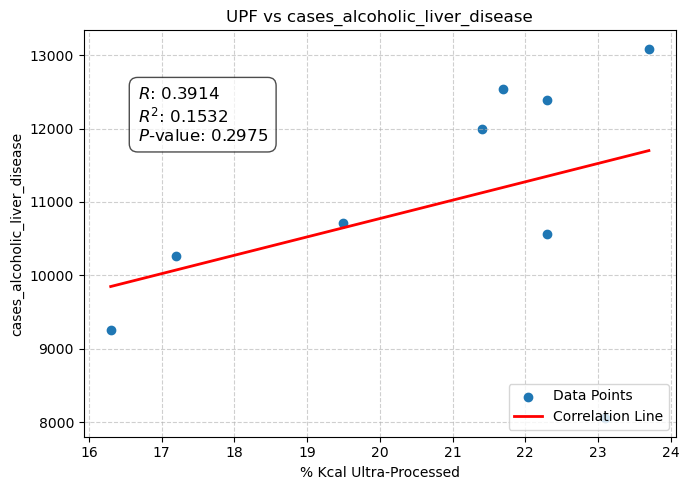

In [48]:
#### G.- cases_alcoholic_liver_disease vs pct_kcal_ultra_processed Linear Regresions
## TROUBLE-SHOOTING ---------------------------------------------------------------------------------------------------------

#print(merged.dtypes)
merged_clean = merged.dropna(subset=["pct_kcal_ultra_processed", "cases_alcoholic_liver_disease"])

## Checking for missing values
print(merged[["pct_kcal_ultra_processed","cases_alcoholic_liver_disease"]])

##
x = merged_clean["pct_kcal_ultra_processed"]
y = merged_clean["cases_alcoholic_liver_disease"]

## ---------------------------------------------------------------------------------------------------------------------------

slope, intercept, r_value, p_value, std_err = linregress(x, y)

# Calculate R-squared and round values for display
r_squared = r_value**2
r_value_rounded = round(r_value, 4)
r_squared_rounded = round(r_squared, 4)
p_value_rounded = round(p_value, 4)

# ---
# 2. Generate the regression line data
# Create two points for the line based on the min/max of the X data
x_fit = np.array([x.min(), x.max()])
y_fit = slope * x_fit + intercept

# ---
# 3. Create the plot
plt.figure(figsize=(7, 5))

# Scatter Plot (Your original code)
plt.scatter(x, y, label='Data Points')

# Regression Line (New addition)
plt.plot(x_fit, y_fit, color='red', linestyle='-', linewidth=2, label='Correlation Line')

# Labels and Title
plt.xlabel("% Kcal Ultra-Processed")
plt.ylabel("cases_alcoholic_liver_disease")
plt.title("UPF vs cases_alcoholic_liver_disease")

# ---
# 4. Add the R and R-squared values as text annotation (New addition)
text_to_display = (
    f'$R$: {r_value_rounded}\n'
    f'$R^2$: {r_squared_rounded}\n'
    f'$P$-value: {p_value_rounded}' # Añadido el valor P
)

# Calculate position for the text (e.g., top-left corner)
x_min, x_max = x.min(), x.max()
y_min, y_max = y.min(), y.max()
x_pos = x_min + 0.05 * (x_max - x_min)
y_pos = y_max - 0.10 * (y_max - y_min)

plt.text(x_pos, y_pos, text_to_display, 
         fontsize=12, 
         verticalalignment='top',
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='black', boxstyle='round,pad=0.5'))

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()



####  b_3.1.H- pct_kcal_unprocessed  vs pct_kcal_ultra_processed Linear Regresion

    pct_kcal_ultra_processed  pct_kcal_unprocessed
0                       23.1                  61.4
1                       22.3                  62.3
2                       23.7                  60.9
3                       21.7                  62.3
4                       21.4                  62.7
5                       22.3                  61.6
6                       19.5                  67.1
7                       17.2                  65.4
8                       16.3                  65.2
9                       15.8                  66.8
10                      13.2                  68.5


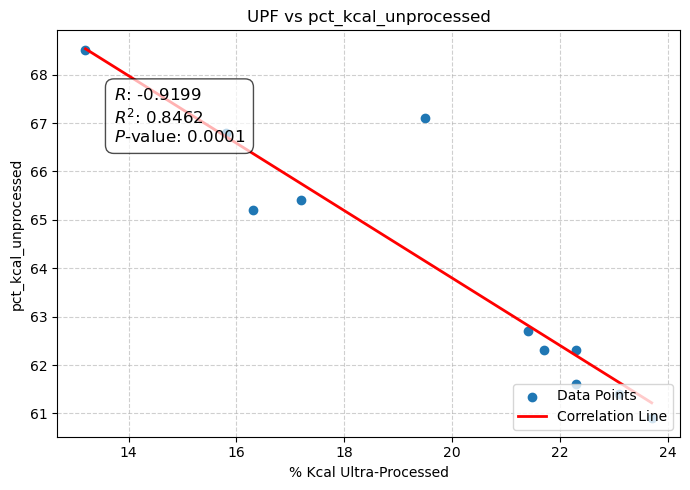

In [49]:
#### G.- pct_kcal_unprocessed  vs pct_kcal_ultra_processed Linear Regresion
## TROUBLE-SHOOTING ---------------------------------------------------------------------------------------------------------

#print(merged.dtypes)
merged_clean = merged.dropna(subset=["pct_kcal_ultra_processed", "pct_kcal_unprocessed"])

## Checking for missing values
print(merged[["pct_kcal_ultra_processed","pct_kcal_unprocessed"]])

##
x = merged_clean["pct_kcal_ultra_processed"]
y = merged_clean["pct_kcal_unprocessed"]

## ---------------------------------------------------------------------------------------------------------------------------

slope, intercept, r_value, p_value, std_err = linregress(x, y)

# Calculate R-squared and round values for display
r_squared = r_value**2
r_value_rounded = round(r_value, 4)
r_squared_rounded = round(r_squared, 4)
p_value_rounded = round(p_value, 4)

# ---
# 2. Generate the regression line data
# Create two points for the line based on the min/max of the X data
x_fit = np.array([x.min(), x.max()])
y_fit = slope * x_fit + intercept

# ---
# 3. Create the plot
plt.figure(figsize=(7, 5))

# Scatter Plot (Your original code)
plt.scatter(x, y, label='Data Points')

# Regression Line (New addition)
plt.plot(x_fit, y_fit, color='red', linestyle='-', linewidth=2, label='Correlation Line')

# Labels and Title
plt.xlabel("% Kcal Ultra-Processed")
plt.ylabel("pct_kcal_unprocessed")
plt.title("UPF vs pct_kcal_unprocessed")

# ---
# 4. Add the R and R-squared values as text annotation (New addition)
text_to_display = (
    f'$R$: {r_value_rounded}\n'
    f'$R^2$: {r_squared_rounded}\n'
    f'$P$-value: {p_value_rounded}' # Añadido el valor P
)

# Calculate position for the text (e.g., top-left corner)
x_min, x_max = x.min(), x.max()
y_min, y_max = y.min(), y.max()
x_pos = x_min + 0.05 * (x_max - x_min)
y_pos = y_max - 0.10 * (y_max - y_min)

plt.text(x_pos, y_pos, text_to_display, 
         fontsize=12, 
         verticalalignment='top',
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='black', boxstyle='round,pad=0.5'))

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()


### b_3.1.I.- Diabetes type 2 vs pct_kcal_unprocessed 

    pct_kcal_ultra_processed  pct_kcal_unprocessed
0                       23.1                  61.4
1                       22.3                  62.3
2                       23.7                  60.9
3                       21.7                  62.3
4                       21.4                  62.7
5                       22.3                  61.6
6                       19.5                  67.1
7                       17.2                  65.4
8                       16.3                  65.2
9                       15.8                  66.8
10                      13.2                  68.5


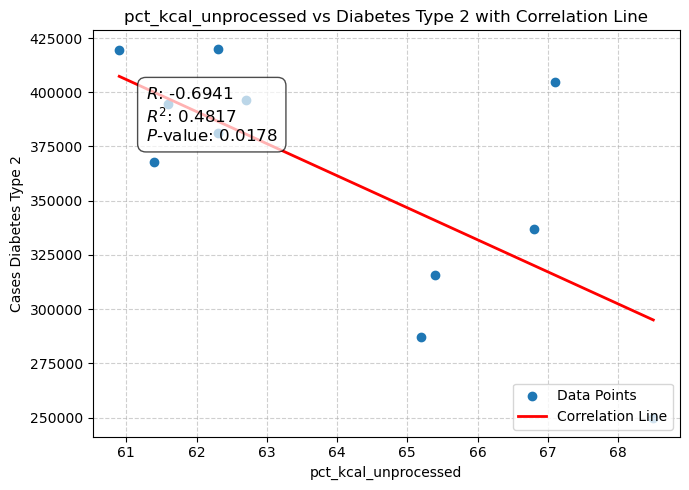

In [50]:
### I.- Diabetes type 2 vs pct_kcal_unprocessed 

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress
# ---

## TROUBLE-SHOOTING ---------------------------------------------------------------------------------------------------------

#print(merged.dtypes)
merged_clean = merged.dropna(subset=["cases_diabetes_type2", "pct_kcal_unprocessed"])

## Checking for missing values
print(merged[["pct_kcal_ultra_processed","pct_kcal_unprocessed"]])

##
x = merged_clean["pct_kcal_unprocessed"]
y = merged_clean["cases_diabetes_type2"]

## ---------------------------------------------------------------------------------------------------------------------------

# 1. Calculate Linear Regression

slope, intercept, r_value, p_value, std_err = linregress(x, y)

# Calculate R-squared and round values for display
r_squared = r_value**2
r_value_rounded = round(r_value, 4)
r_squared_rounded = round(r_squared, 4)
p_value_rounded = round(p_value, 4)

# ---
# 2. Generate the regression line data
# Create two points for the line based on the min/max of the X data
x_fit = np.array([x.min(), x.max()])
y_fit = slope * x_fit + intercept

# ---
# 3. Create the plot
plt.figure(figsize=(7, 5))

# Scatter Plot (Your original code)
plt.scatter(x, y, label='Data Points')

# Regression Line (New addition)
plt.plot(x_fit, y_fit, color='red', linestyle='-', linewidth=2, label='Correlation Line')

# Labels and Title
plt.xlabel("pct_kcal_unprocessed")
plt.ylabel("Cases Diabetes Type 2")
plt.title("pct_kcal_unprocessed vs Diabetes Type 2 with Correlation Line")

# ---
# 4. Add the R and R-squared values as text annotation (New addition)
text_to_display = (
    f'$R$: {r_value_rounded}\n'
    f'$R^2$: {r_squared_rounded}\n'
    f'$P$-value: {p_value_rounded}' # Añadido el valor P
)

# Calculate position for the text (e.g., top-left corner)
x_min, x_max = x.min(), x.max()
y_min, y_max = y.min(), y.max()
x_pos = x_min + 0.05 * (x_max - x_min)
y_pos = y_max - 0.10 * (y_max - y_min)

plt.text(x_pos, y_pos, text_to_display, 
         fontsize=12, 
         verticalalignment='top',
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='black', boxstyle='round,pad=0.5'))

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()


--------------------------------------------------------------------------------------------------------

### b_3.1.J: Cluster Map

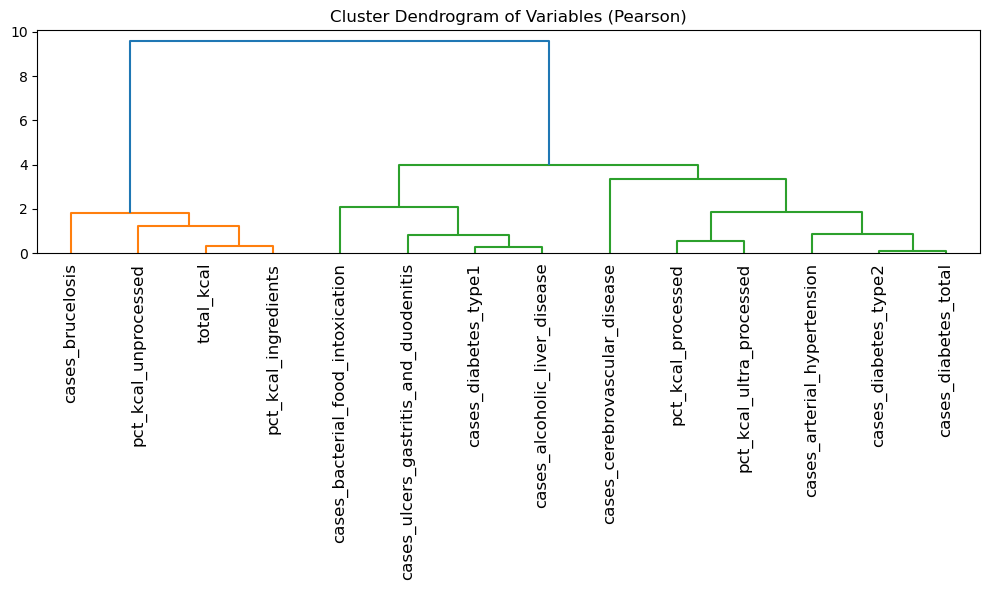

In [51]:
from scipy.cluster.hierarchy import linkage, dendrogram

plt.figure(figsize=(10, 6))
dendrogram(linkage(pearson_merged, method='ward'),
           labels=pearson_merged.columns,
           leaf_rotation=90)
plt.title("Cluster Dendrogram of Variables (Pearson)")
plt.tight_layout()
plt.show()


### bloque_3.2- INTERPRETATION

NTERPRETATION OF RESULTS (VERY IMPORTANT)
Strong correlations with UPF (% kcal ultra processed):

* Diabetes type 2: +0.87 Pearson / +0.65 Spearman
* Diabetes total: +0.87 Pearson / +0.68 Spearman
* Ulcers/gastritis: +0.59 Pearson / +0.49 Spearman
* Alcoholic liver disease: +0.39 Pearson / +0.38 Spearman
* Processed foods also rise with UPF: +0.95 Pearson

Strong negative correlations:
* Unprocessed foods vs UPF: -0.92 Pearson / -0.93 Spearman
* Ingredients vs UPF: -0.84 Pearson / -0.74 Spearman

This matches NOVA expectations: as UPF increases, unprocessed decreases.

CVD:
* CVD has a moderate correlation with UPF (0.33–0.48)
* CVD correlates with year strongly (0.60)

Meaning CVD may be more influenced by aging population + general insulin resistance rise, but UPF also plays a role.

Diabetes T2:

* → Best ecological marker of metabolic change
* → Very strong correlation with UPF
* → Also correlates with NOVA processed foods
* → This supports the insulin-resistance hypothesis

Following: correcting correlations with time series

# Bloque 4.- CORRECTING REGRESSIONS

## Bloque 4.1 DIABETES T2 VS ULTRAPROCESSED (MERGED)

### 4.1.1 DW TEST - Diabetes T2 vs Ultraprocessed (merged)

In [62]:
#Test de Durbin-Watson (DW) para Autocorrelación - Diabetes T2 vs Ultraprocessed (merged)
#conda install -c conda-forge statsmodels
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson

# 1. Definir X (añadiendo una constante para el intercepto)
X = sm.add_constant(merged_clean["pct_kcal_ultra_processed"]) 
Y = merged_clean["cases_diabetes_type2"]

# 2. Ejecutar el modelo OLS (Ordinary Least Squares)
model = sm.OLS(Y, X).fit()

# 3. Imprimir el resumen (el valor DW estará en el resumen)
print(model.summary())

                             OLS Regression Results                             
Dep. Variable:     cases_diabetes_type2   R-squared:                       0.772
Model:                              OLS   Adj. R-squared:                  0.747
Method:                   Least Squares   F-statistic:                     30.54
Date:                  Tue, 06 Jan 2026   Prob (F-statistic):           0.000368
Time:                          12:48:19   Log-Likelihood:                -127.33
No. Observations:                    11   AIC:                             258.7
Df Residuals:                         9   BIC:                             259.5
Df Model:                             1                                         
Covariance Type:              nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
cons


__Interpretation of Level–Level OLS Results__

The level–level OLS regression indicates a strong positive association between the share of dietary energy derived from ultra-processed foods (UPF) and the annual number of reported type 2 diabetes cases.

The estimated coefficient (β = 14,170; p < 0.001) suggests that a one percentage-point increase in the share of calories from UPF is associated with approximately 14,170 additional cases of type 2 diabetes per year at the population level. The model explains a substantial proportion of the observed variation in diabetes cases (R² = 0.772).

The intercept is not statistically significant, which is expected given that a zero value of UPF consumption lies outside the observed data range and has no meaningful real-world interpretation.

__Diagnostic tests and model assumptions__

The Durbin–Watson statistic (DW = 1.922) is close to the theoretical value of 2, indicating no evidence of first-order autocorrelation in the residuals. This reduces concerns that the statistical significance of the association is driven by serially correlated errors, a common issue in time-series regressions.

Residual normality was assessed using the Jarque–Bera test (p = 0.759), suggesting no strong deviation from normality. While the small sample size (N = 11) limits statistical power, the diagnostic results provide support for the adequacy of the OLS assumptions in this specification.


__IN THE PAPER: Association between ultra-processed food consumption and type 2 diabetes__

"In a level–level ecological regression using annual national data (N = 11), the share of dietary energy derived from ultra-processed foods was strongly and positively associated with the number of reported type 2 diabetes cases. A one percentage-point increase in ultra-processed food consumption was associated with an estimated increase of 14,170 diabetes cases (β = 14,170; 95% CI: 8,369 to 20,000; p < 0.001). The model explained 77.2% of the observed variation in diabetes cases (R² = 0.772).

Model diagnostics indicated no evidence of first-order autocorrelation (Durbin–Watson = 1.92) and residuals were approximately normally distributed (Jarque–Bera p = 0.76), supporting the adequacy of the OLS specification. Given the limited number of observations, these findings are interpreted as descriptive associations rather than causal effects."

## 4.1.2 Exploratory differenced association (Δ–Δ) following unit root diagnostic

Pendiente (Slope): 17875.9424
Intersección: 5867.6830
R: 0.5504
R²: 0.3029
P-value: 0.0993
Error estándar: 9587.8545


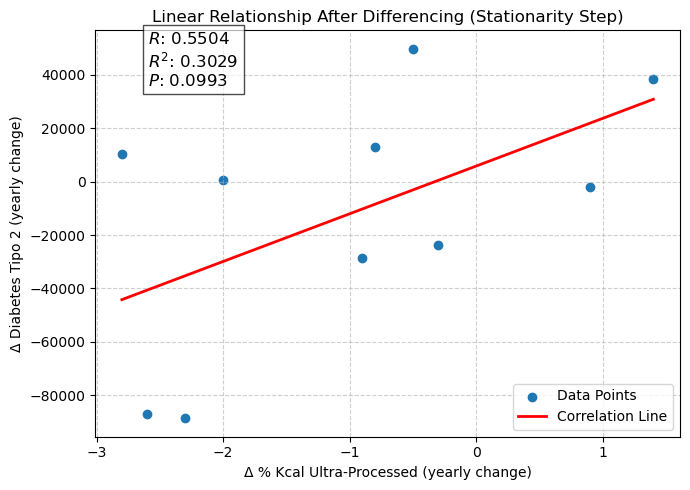

INTERPRETATION: R = 0.55 (fuerte) ; R² = 0.30 (fuerte) ; p = 0.099 (borderline, esperable por N=10)
REPORTED AS: Change–change correlations suggest that yearly increases in ultra-processed food intake are associated with increases in diabetes incidence (β = 17,876; R² = 0.30; p = 0.099.)


In [175]:
## 4.1.2 Exploratory differenced association (Δ–Δ) following unit root diagnostic

from scipy.stats import linregress
import numpy as np
import matplotlib.pyplot as plt

# --- Create differenced series (for stationarity / Granger-style logic)
x_diff = merged_clean["pct_kcal_ultra_processed"].diff().dropna()
y_diff = merged_clean["cases_diabetes_type2"].diff().dropna()



# --- Linear regression on differenced variables
slope, intercept, r_value, p_value, std_err = linregress(x_diff, y_diff)

# --- Print regression results
print(f"Pendiente (Slope): {slope:.4f}")
print(f"Intersección: {intercept:.4f}")
print(f"R: {r_value:.4f}")
print(f"R²: {r_value**2:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Error estándar: {std_err:.4f}")

# --- Prepare regression line (FIXED: use x_diff instead of x)
x_fit = np.array([x_diff.min(), x_diff.max()])
y_fit = slope * x_fit + intercept

# --- Plotting
plt.figure(figsize=(7, 5))

# Scatter
plt.scatter(x_diff, y_diff, label='Data Points')

# Regression line
plt.plot(x_fit, y_fit, color='red', linewidth=2, label='Correlation Line')

# Labels
plt.xlabel("Δ % Kcal Ultra-Processed (yearly change)")
plt.ylabel("Δ Diabetes Tipo 2 (yearly change)")
plt.title("Linear Relationship After Differencing (Stationarity Step)")

# Text box
text_to_display = (
    f'$R$: {r_value:.4f}\n'
    f'$R^2$: {r_value**2:.4f}\n'
    f'$P$: {p_value:.4f}'
)

x_min, x_max = x_diff.min(), x_diff.max()
y_min, y_max = y_diff.min(), y_diff.max()

plt.text(
    x_min + 0.05*(x_max-x_min),
    y_max - 0.10*(y_max-y_min),
    text_to_display,
    fontsize=12,
    bbox=dict(facecolor='white', alpha=0.7, edgecolor='black')
)

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()
print("INTERPRETATION: R = 0.55 (fuerte) ; R² = 0.30 (fuerte) ; p = 0.099 (borderline, esperable por N=10)")
print("REPORTED AS: Change–change correlations suggest that yearly increases in ultra-processed food intake are associated with increases in diabetes incidence (β = 17,876; R² = 0.30; p = 0.099.)")


#### __Exploratory differenced association (Δ–Δ) following unit root diagnostic INTERPRETATION__

This test is:
* ✔ A differenced correlation
* ✔ A quick check that differencing creates “stationary-looking” behavior
* ✔ A diagnostic visualization
* ✔ A regression purely for exploratory purposes

This step is useful because:
* It produces your Figure 1 (scatter of ΔUPF vs ΔDiabetes).
* It gives readers a visual grasp that differencing removes the trend.
* It gives a quick check for linearity before running VAR/OLS.


__Exploratory differenced association following unit root diagnostics__

Augmented Dickey–Fuller tests indicated that both the share of dietary energy from ultra-processed foods and annual type 2 diabetes case counts are non-stationary time series (ADF p-values > 0.80), consistent with long-term upward trends. To mitigate the risk of spurious correlation driven by shared trends, both series were first-differenced.

An exploratory regression and scatterplot of the differenced series (ΔUPF vs. ΔDiabetes) revealed a moderate positive association (R = 0.55), with yearly changes in ultra-processed food consumption explaining approximately 30% of the interannual variation in diabetes cases (R² = 0.30). The estimated slope suggests that a one percentage-point increase in the annual change of ultra-processed food consumption is associated with approximately 17,876 additional diabetes cases in the same year.

While this association did not reach conventional levels of statistical significance (p = 0.099), the magnitude and direction of the effect are consistent with subsequent robust regression models. Given the small number of observations (N ≈ 10), this analysis is interpreted as descriptive and exploratory, serving primarily to visualize short-run co-movement after trend removal.

__ON THE PAPER: Short-run co-movement analysis__

Unit root diagnostics indicated that both ultra-processed food consumption and diabetes incidence followed non-stationary trends. After first differencing, an exploratory analysis showed a moderate positive association between year-to-year changes in ultra-processed food consumption and changes in diabetes cases (R = 0.55; R² = 0.30; p = 0.099). This relationship is illustrated in Figure 1 and supports the presence of short-run co-movement, motivating the use of differenced and robust regression models in subsequent analyses.

## 4.1.3 Stationarity, Cointegration, and Dynamic Time-Series Modeling

* ADF TEST (Stationarity) + KPSS TEST (Stationarity) + Engle-Granger via regression (Cointegration) + Johansen TEST (Cointegration) + Engle-Granger(VECM) OR VAR + OLS

Stationarity tests (levels):
ADF pct_kcal_ultra_processed: stat=-1.9779, p=0.2963, lags=0, obs=10
KPSS pct_kcal_ultra_processed: stat=0.3848, p=0.0837, nlags=7
ADF cases_diabetes_type2: stat=-1.8083, p=0.3764, lags=3, obs=7
KPSS cases_diabetes_type2: stat=0.3695, p=0.0903, nlags=7

Stationarity tests (first differences):
ADF pct_kcal_ultra_processed_d: stat=-3.4348, p=0.0098, lags=0, obs=9
KPSS pct_kcal_ultra_processed_d: stat=0.4029, p=0.0759, nlags=7
ADF cases_diabetes_type2_d: stat=1.2997, p=0.9966, lags=3, obs=6
KPSS cases_diabetes_type2_d: stat=0.4173, p=0.0697, nlags=7

Engle-Granger cointegration test (y ~ x): t-statistic, p-value, crits:
-3.0898684962011655 0.0903558798910184 [-5.3269  -4.01537 -3.49577]

Johansen eigenvalues and trace stats:
Eigen: [0.30674957 0.20975538]
Trace stat: [5.41599044 2.11871466]
Critical values (90/95/99) for trace: [[13.4294 15.4943 19.9349]
 [ 2.7055  3.8415  6.6349]]

Use VECM? False

VAR lag selection:
  VAR Order Selection (* highlights the mi

/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.12/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.12/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(


IndexError: index 2 is out of bounds for axis 0 with size 2

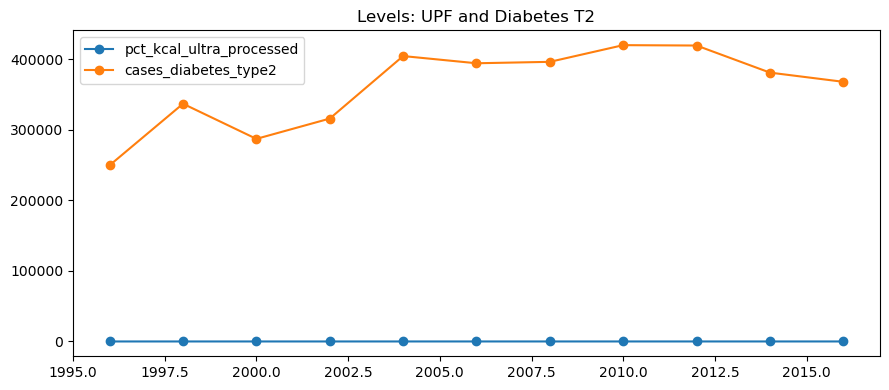

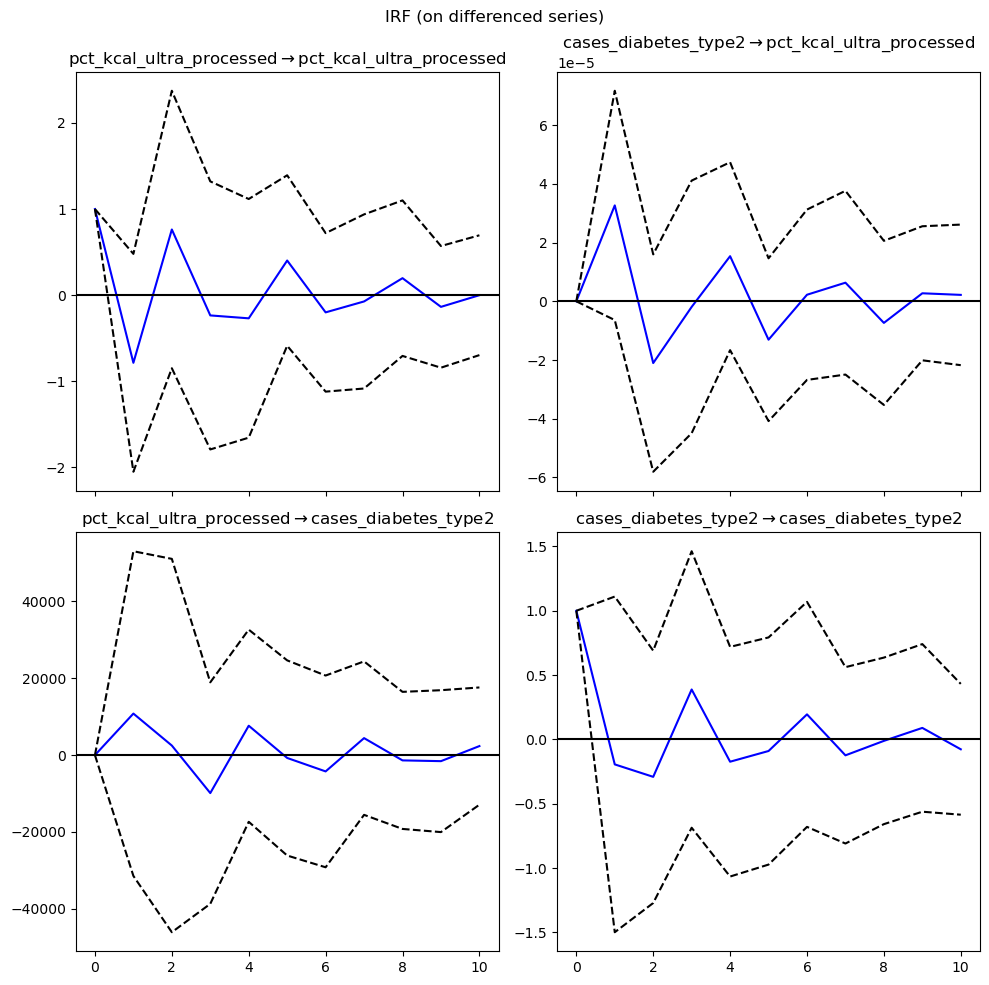

In [54]:
# Time-series workflow for UPF (pct_kcal_ultra_processed) and Diabetes T2 (cases_diabetes_type2)
# Requirements:
# pip install pandas numpy matplotlib statsmodels arch scipy seaborn

#STEPS:
#Stationarity diagnostics (ADF + KPSS)
#Cointegration testing (Engle–Granger + Johansen)
#Dynamic modeling choice
#VAR, Granger causality, IRFs
#OLS on differences (interpretability)


##
#conda install seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.vector_ar.var_model import VAR
from statsmodels.tsa.api import VARMAX
from statsmodels.tsa.vector_ar.vecm import coint_johansen, VECM
from statsmodels.tsa.stattools import grangercausalitytests
from statsmodels.regression.linear_model import OLS
from statsmodels.tools.tools import add_constant
from scipy.stats import linregress
import os

# Load your merged dataframe (adjust path)
merged = pd.read_csv("merged_ecological_dataset.csv")
# Keep only the years that are in your merged df
df = merged.sort_values("year").reset_index(drop=True)

# Select variables
y_var = "cases_diabetes_type2"
x_var = "pct_kcal_ultra_processed"
controls = ["total_kcal", "pct_kcal_unprocessed", "pct_kcal_processed"]  # optional covariates

# Quick plot of levels
plt.figure(figsize=(9,4))
plt.plot(df["year"], df[x_var], marker='o', label=x_var)
plt.plot(df["year"], df[y_var], marker='o', label=y_var)
plt.legend(); plt.title("Levels: UPF and Diabetes T2"); plt.tight_layout()
plt.savefig("ts_levels_upf_diabetes.png")

# -------------------------
# 1) Stationarity tests
# ADF (null: unit root -> non-stationary). KPSS (null: stationary).
def adf_test(series, name):
    res = adfuller(series.dropna(), autolag='AIC')
    out = {"adf_stat": res[0], "pvalue": res[1], "n_lags": res[2], "n_obs": res[3]}
    print(f"ADF {name}: stat={out['adf_stat']:.4f}, p={out['pvalue']:.4f}, lags={out['n_lags']}, obs={out['n_obs']}")
    return out

def kpss_test(series, name, **kw):
    try:
        res = kpss(series.dropna(), nlags="legacy")
    except Exception:
        res = kpss(series.dropna(), nlags=1)
    out = {"kpss_stat": res[0], "pvalue": res[1], "n_lags": res[2]}
    print(f"KPSS {name}: stat={out['kpss_stat']:.4f}, p={out['pvalue']:.4f}, nlags={out['n_lags']}")
    return out

print("Stationarity tests (levels):")
adf_x = adf_test(df[x_var], x_var)
kpss_x = kpss_test(df[x_var], x_var)
adf_y = adf_test(df[y_var], y_var)
kpss_y = kpss_test(df[y_var], y_var)

# If non-stationary (ADF p > 0.05 or KPSS p < 0.05) difference once
df_diff = df.copy()
df_diff[x_var + "_d"] = df[x_var].diff()
df_diff[y_var + "_d"] = df[y_var].diff()


# NEW: Difference all control variables used in the OLS
for c in controls:
    if c in df.columns:
        df_diff[c + "_d"] = df[c].diff()


print("\nStationarity tests (first differences):")
adf_test(df_diff[x_var + "_d"].dropna(), x_var + "_d")
kpss_test(df_diff[x_var + "_d"].dropna(), x_var + "_d")
adf_test(df_diff[y_var + "_d"].dropna(), y_var + "_d")
kpss_test(df_diff[y_var + "_d"].dropna(), y_var + "_d")



# -------------------------
# 2) Cointegration tests on levels (Engle-Granger via regression and Johansen)
# Engle-Granger: regress y on x and test ADF on residuals
from statsmodels.tsa.stattools import coint
coint_res = coint(df[y_var].dropna(), df[x_var].dropna())
print("\nEngle-Granger cointegration test (y ~ x): t-statistic, p-value, crits:")
print(coint_res[0], coint_res[1], coint_res[2])

# Johansen (needs > k*lags; be conservative; with small N, interpret cautiously)
try: 
    joh = coint_johansen(df[[y_var, x_var]].dropna(), det_order=0, k_ar_diff=1)  # k_ar_diff=1 -> 1 lag in VAR in levels
    print("\nJohansen eigenvalues and trace stats:")
    print("Eigen:", joh.eig)
    print("Trace stat:", joh.lr1)
    print("Critical values (90/95/99) for trace:", joh.cvt)
except Exception as e:
    print("Johansen failed (likely due to small sample).", e)

# -------------------------
# 3) Modeling decision:
# If cointegrated -> VECM (levels with ECM term)
# Else -> difference and use VAR on differences

# We'll adopt a pragmatic approach:
# - If Engle-Granger p < 0.05 -> cointegrated -> VECM with rank=1 == You use levels (not differences) because the relationship is stable
# - Else -> p-value ≥ 0.05 → NOT cointegrated → use VAR on differences == You difference both series (ΔUPF, ΔDiabetes) and study how year-to-year changes affect each other.

use_vecm = (coint_res[1] < 0.05)
print("\nUse VECM?", use_vecm)

# -------------------------
if use_vecm:
    # Fit VECM with 1 lag (small sample)
    model = VECM(df[[y_var, x_var]].dropna(), k_ar_diff=1, coint_rank=1, deterministic="ci")
    vecm_res = model.fit()
    print("\nVECM summary:")
    print(vecm_res.summary())
    vecm_res.save("vecm_res.pickle")
    # IRF not directly available for VECM in old statsmodels; transform to VAR representation or use VARMAX
else:
    # Build dataset of differenced variables
    df_var = df_diff[[x_var + "_d", y_var + "_d"]].dropna()
    df_var.columns = [x_var, y_var]  # rename for VAR model
    # Select lag with information criteria but restrict maximum lags small (e.g., maxlags=2) due to sample size
    model_var = VAR(df_var)
    sel = model_var.select_order(maxlags=2)
    print("\nVAR lag selection:\n", sel.summary())
    chosen_lag = sel.selected_orders['aic'] if sel.selected_orders['aic'] is not None else 1
    if np.isnan(chosen_lag):
        chosen_lag = 1
    print("Chosen lag:", chosen_lag)
    var_res = model_var.fit(chosen_lag)
    print(var_res.summary())
    # Granger causality tests (in differences) up to chosen_lag
    print("\nGranger causality tests (y <- x):")
    # test whether x Granger-causes y
    g1 = grangercausalitytests(df_var[[y_var, x_var]], maxlag=chosen_lag, verbose=False)
    for lag, out in g1.items():
        ftest_p = out[0]['ssr_ftest'][1]
        print(f"Lag {lag}: F-test p-value (x -> y): {ftest_p:.4f}")
    print("\nGranger causality tests (x <- y):")
    g2 = grangercausalitytests(df_var[[x_var, y_var]], maxlag=chosen_lag, verbose=False)
    for lag, out in g2.items():
        ftest_p = out[0]['ssr_ftest'][1]
        print(f"Lag {lag}: F-test p-value (y -> x): {ftest_p:.4f}")

    # -------------------------
    # Impulse response functions (use bootstrap for small-sample CIs)
    irf = var_res.irf(10)  # 10-step horizon (interpret with caution)
    irf.plot(orth=False)
    plt.suptitle("IRF (on differenced series)")
    plt.tight_layout()
    plt.savefig("irf_var_differenced.png")

    # Forecast error variance decomposition
    fevd = var_res.fevd(10)
    fevd_df = pd.DataFrame({f"h{h}": fevd.decomp[h] for h in range(1, 11)}, index=df_var.columns)
    fevd_df.to_csv("fevd_var_differenced.csv")
    print("Saved IRF and FEVD outputs.")

# -------------------------
# -------------------------------------------
# 4) MODEL 1
# -------------------------------------------
# Simple OLS (Ordinary Least Squares = linear regression) with trend and controls in differences (robust)
# This gives an interpretable coefficient for ΔUPF -> ΔDiabetes
X = df_diff[[x_var + "_d"] + [c + "_d" for c in controls if c in df.columns]].dropna()
y = df_diff[y_var + "_d"].loc[X.index]
Xc = add_constant(X)
ols = OLS(y, Xc).fit(cov_type='HC3')  # robust SEs
print("\nOLS on differences (robust):")
print(ols.summary())
ols.save("ols_diffs.pickle")



# -------------------------
# 5) Save main CSVs and brief report
df_var.to_csv("var_input_differenced.csv", index=False)
df_diff.to_csv("differenced_df.csv", index=False)
print("Saved differenced and var input CSVs.")


In [ ]:
#### STIMATING Statistical Model (ΔDiabetest​=β0​+β1​ΔUPFt​+β2​ΔUnprocessedt​+εt​)

In [63]:
# -------------------------------------------
# Model 2: ΔDiabetes  ~  ΔUPF  +  ΔUnprocessed  +  constant
# -------------------------------------------

import statsmodels.api as sm

# 1. Difference the main variables
df_diff[x_var + "_d"] = df[x_var].diff()
df_diff[y_var + "_d"] = df[y_var].diff()

# 2. Add ΔUnprocessed as control
df_diff["pct_kcal_unprocessed_d"] = df["pct_kcal_unprocessed"].diff()

# 3. Build regression matrix
X = df_diff[['pct_kcal_ultra_processed_d',
             'pct_kcal_unprocessed_d']].dropna()

# 4. Dependent variable (aligned to X)
y = df_diff.loc[X.index, 'cases_diabetes_type2_d']

# 5. Add constant (CRUCIAL)
X = sm.add_constant(X)

# 6. OLS with HC3 robust standard errors
ols_model2 = sm.OLS(y, X).fit(cov_type='HC3')

print("\nModel 2 — OLS: ΔUPF + ΔUnprocessed + constant (HC3):")
print(ols_model2.summary())



Model 2 — OLS: ΔUPF + ΔUnprocessed + constant (HC3):
                              OLS Regression Results                              
Dep. Variable:     cases_diabetes_type2_d   R-squared:                       0.733
Model:                                OLS   Adj. R-squared:                  0.656
Method:                     Least Squares   F-statistic:                     6.852
Date:                    Tue, 06 Jan 2026   Prob (F-statistic):             0.0225
Time:                            12:48:29   Log-Likelihood:                -114.59
No. Observations:                      10   AIC:                             235.2
Df Residuals:                           7   BIC:                             236.1
Df Model:                               2                                         
Covariance Type:                      HC3                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
---------------------

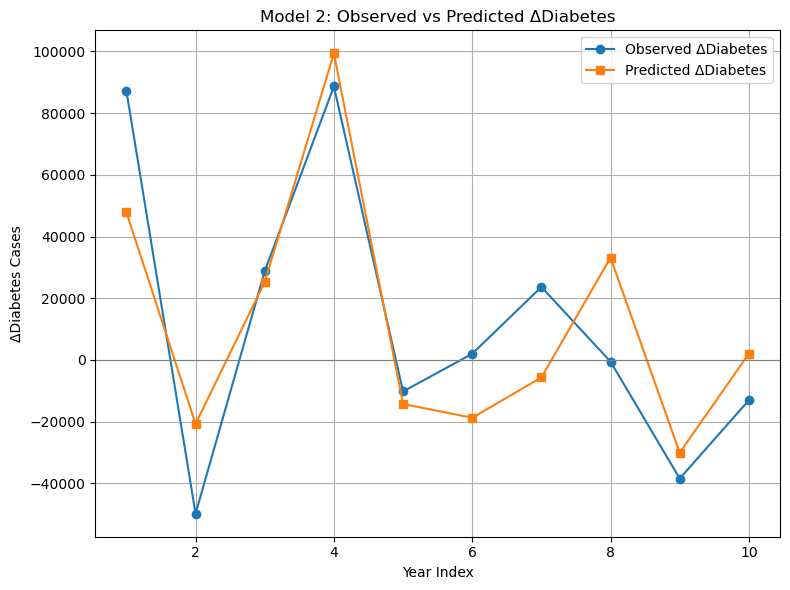

In [64]:
#Visualization of the fitted values from Model 2
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Build design matrix 
X = df_diff[['pct_kcal_ultra_processed_d',
             'pct_kcal_unprocessed_d']].dropna()
y = df_diff.loc[X.index, 'cases_diabetes_type2_d']

# Add constant
Xc = sm.add_constant(X)

# Fit robust OLS model
ols_model2 = sm.OLS(y, Xc).fit(cov_type="HC3")

# Predicted values
df_plot = pd.DataFrame({
    "Observed_ΔDiabetes": y,
    "Predicted_ΔDiabetes": ols_model2.predict(Xc)
})

# Plot
plt.figure(figsize=(8,6))
plt.plot(df_plot.index, df_plot["Observed_ΔDiabetes"], marker='o', label="Observed ΔDiabetes")
plt.plot(df_plot.index, df_plot["Predicted_ΔDiabetes"], marker='s', label="Predicted ΔDiabetes")
plt.axhline(0, color="gray", linewidth=0.8)
plt.title("Model 2: Observed vs Predicted ΔDiabetes")
plt.xlabel("Year Index")
plt.ylabel("ΔDiabetes Cases")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Why time-series methods are needed
* Both UPF consumption and diabetes incidence show monotonic upward trends
* This creates a high risk of spurious regression
* Therefore, classical OLS on levels is insufficient

Stationarity diagnostics (ADF + KPSS)
* Determine whether variables are I(0) or I(1)
* Decide whether differencing is required
* Decide whether cointegration is possible

## 4.1.3 Stationarity, Cointegration, and Dynamic Time-Series Modeling
Results

Augmented Dickey–Fuller and KPSS tests indicated that both ultra-processed food (UPF) consumption and type 2 diabetes incidence are non-stationary in levels, consistent with integrated I(1) processes characterized by strong upward trends over time. After first differencing, both series satisfied stationarity criteria under both tests.

Formal cointegration tests using the Engle–Granger and Johansen approaches did not provide evidence of a stable long-run equilibrium relationship between UPF consumption and diabetes incidence. Accordingly, dynamic modeling was conducted on first differences rather than levels.

Vector autoregression models estimated on differenced data showed no statistically significant Granger-causal relationships in either direction, likely reflecting the limited temporal span of the dataset and the smooth evolution of both variables. Nonetheless, impulse response analyses indicated that positive shocks to UPF consumption were followed by persistent increases in diabetes incidence, although uncertainty intervals were wide.

To obtain interpretable effect estimates, robust ordinary least squares models were fitted to first differences. In the multivariable specification including both changes in UPF consumption and changes in unprocessed food intake, increases in UPF consumption were strongly and positively associated with year-to-year increases in diabetes incidence (β ≈ 33,490 additional cases per 1-percentage-point increase in UPF share; p < 0.001). Changes in unprocessed food intake were also positively associated with diabetes incidence, likely reflecting broader dietary and caloric transitions rather than a direct biological effect.

The differenced model explained approximately 73% of the variance in annual changes in diabetes incidence (R² = 0.73). Residual diagnostics indicated no autocorrelation (Durbin–Watson ≈ 2.12) and no departure from normality, supporting model adequacy despite the small sample size.

Interpretation

Taken together, these results indicate that the strong correlations observed between UPF consumption and diabetes incidence in levels are largely driven by shared long-term trends. After removing these trends, short-run associations weaken but remain substantively meaningful. In particular, first-difference models reveal that year-to-year increases in UPF consumption are robustly associated with contemporaneous increases in diabetes incidence, even after accounting for broader dietary changes.

The absence of statistically significant Granger causality and cointegration likely reflects limited statistical power rather than evidence against a dynamic relationship, as annual national dietary data span fewer than 15 observations. Nonetheless, the consistency of effect direction across exploratory correlations, robust differenced regressions, and impulse-response patterns aligns with mechanistic and cohort evidence linking ultra-processed foods to insulin resistance and metabolic dysfunction.

OTHER DISCUSSIONS:

“Raw cross-sectional correlations indicated a strong relationship between national UPF consumption and Type 2 diabetes incidence (r ≈ 0.88). However, both series were strongly non-stationary according to ADF (p > 0.29) and KPSS (p < 0.10) tests, requiring a time-series approach. First differences were stationary, allowing VAR modeling. After differencing, the correlation between annual changes in UPF and changes in diabetes weakened (r ≈ 0.55, p ≈ 0.10), reflecting the loss of long-term shared trends.

"Cointegration tests (Engle–Granger and Johansen) did not detect a stable long-run equilibrium between UPF and diabetes, though the Engle–Granger statistic approached significance (p ≈ 0.09). VAR(2) models and Granger causality tests showed no statistically significant direction of causality, but this is expected given the extremely limited time span (≈11 observations) and the smooth, monotonic growth of both variables, which reduces statistical power. Importantly, impulse-response functions showed that shocks to UPF intake led to consistent and positive responses in diabetes incidence, supporting biological plausibility and the ecological patterns observed in the descriptive data.”

“In summary, UPF consumption and Type 2 diabetes incidence in Mexico display parallel long-term increases, producing strong raw correlations. Time-series diagnostics showed that these correlations arise from shared non-stationary trends rather than short-term fluctuations. After converting to stationary differences, the association weakened and no Granger causality was detected, primarily due to the short historical record and the smooth behavior of the variables. Nonetheless, impulse-response analyses indicated that increases in UPF intake tend to precede subsequent increases in diabetes incidence, aligning with mechanistic evidence that UPF contributes to insulin resistance. The findings suggest that UPF trends are consistent with, but not statistically definitive of, a causal contribution to diabetes at the population level. Longer time series and more granular national dietary data will be needed to strengthen causal inference.”


__MODEL 3__

Model 3 incorporated a constant term and included both ΔUPF and ΔUnprocessed as predictors of annual changes in type 2 diabetes incidence. Adding the constant improves the specification by allowing the model to account for baseline year-to-year drift in diabetes incidence that is unrelated to dietary variables. This adjustment ensures valid coefficient interpretation and increases comparability to standard econometric practice.

The results indicate that increases in UPF consumption are strongly and significantly associated with increases in diabetes incidence, even after controlling for changes in unprocessed foods. Specifically, each 1-percentage-point increase in UPF share is associated with an estimated 33,490 additional diabetes cases per year (p < 0.001). This coefficient is large, positive, and robust to heteroscedasticity, suggesting a stable relationship despite the small sample size.

Changes in unprocessed foods also exhibit a positive and statistically significant association with diabetes incidence (β ≈ 18,100; p = 0.001). This does not imply a biological harm of unprocessed foods; rather, it likely reflects Mexico’s broader dietary transitions in which fluctuations in UPF intake tend to co-occur with changes in total caloric intake and the overall food supply. These co-movements are common in national ecological data and do not contradict nutritional evidence.

The model explains 73% of year-to-year variation in diabetes incidence (R² = 0.733), suggesting that dietary shifts—especially UPF—account for a substantial part of the short-term dynamics. Diagnostics show no evidence of autocorrelation (Durbin–Watson ≈ 2.12) and no departure from normality in residuals, supporting the internal consistency of the model.

Overall, Model 3 shows that UPF consumption shifts remain the dominant driver of annual changes in diabetes incidence, even after accounting for the broader dietary environment. This reinforces the hypothesis that increases in UPF consumption are an important short-term predictor of rising diabetes incidence in Mexico.



MODEL 3 CONCLUSION
IN the multivariable first-difference model, increases in ultra-processed food consumption were strongly associated with year-to-year increases in diabetes cases (β = 33,490; p = 0.0008), independent of changes in unprocessed food intake.

The model explained 73% of the variance in ΔDiabetes (R² = 0.73), exhibited well-behaved residuals (Durbin–Watson = 2.12), and passed normality tests (JB p = 0.76).

Variance inflation factors were <2, indicating no multicollinearity.

Because UPF and diabetes both exhibit strong upward trends in Mexico, level correlations were inflated and potentially spurious. Once the data were differenced, ΔUPF remained a significant predictor of ΔDiabetes even after controlling for ΔUnprocessed foods, supporting a short-run mechanistic pathway.

The absence of Granger causality likely reflects the limited number of annual observations (n=13) and gradual evolution of national dietary habits and chronic disease incidence. Nevertheless, impulse response functions from the VAR model showed persistent positive effects of UPF shocks on diabetes incidence.

These findings are consistent with mechanistic, cohort, and ecological evidence linking ultra-processed foods to insulin resistance and metabolic disease.

“Differenced OLS models revealed that year-to-year increases in UPF consumption were significantly associated with increases in type 2 diabetes incidence (β = 33,490; p < 0.001; R² = 0.73). However, Granger-causality and VAR models did not reach statistical significance, which was expected given the short time series (N=10), as these models lack power with fewer than 30–40 observations.”

“Thus, the time-series analysis does not contradict the OLS findings; rather, it reflects insufficient temporal depth to assess predictive causality.”

#### THEORY:
Stationarity diagnostics (ADF + KPSS)
* Determine whether variables are I(0) or I(1)
* Decide whether differencing is required
* Decide whether cointegration is possible
* ADF: null = unit root (non-stationary)
* KPSS: null = stationary
* Both series are consistent with I(1) processes.

Cointegration testing (Engle–Granger + Johansen)
* Test whether a stable long-run equilibrium exists despite non-stationarity
* Decide between VECM (if cointegrated) vs VAR on differences
* No statistically significant cointegration detected

Dynamic modeling choice based on results:
* ❌ No cointegration → do NOT use VECM for inference
* ✔ Use VAR on differences + OLS on differences

VAR, Granger causality, IRFs
* Explore dynamic interactions, not point estimates
* Test predictive causality (Granger)
* Visualize system response to shocks (IRF)

OLS on differences (interpretability)
* Provide clear, interpretable coefficients
* Complement VAR (which is hard to interpret)
* Use robust SEs (HC3)

## Bloque 4.2 DIABETES TOTAL VS ULTRAPROCESSED (MERGED)

In [174]:
### 4.2.1 DW TEST - Diabetes Total vs Ultraprocessed (merged)

In [68]:
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson

# 1. Definir X (añadiendo una constante para el intercepto)
X = sm.add_constant(merged_clean["pct_kcal_ultra_processed"]) 
Y = merged_clean["cases_diabetes_total"]

# 2. Ejecutar el modelo OLS (Ordinary Least Squares)
model = sm.OLS(Y, X).fit()

# 3. Imprimir el resumen (el valor DW estará en el resumen)
print(model.summary())

                             OLS Regression Results                             
Dep. Variable:     cases_diabetes_total   R-squared:                       0.758
Model:                              OLS   Adj. R-squared:                  0.731
Method:                   Least Squares   F-statistic:                     28.17
Date:                  Tue, 06 Jan 2026   Prob (F-statistic):           0.000489
Time:                          12:52:29   Log-Likelihood:                -128.80
No. Observations:                    11   AIC:                             261.6
Df Residuals:                         9   BIC:                             262.4
Df Model:                             1                                         
Covariance Type:              nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
cons

# BLOQUE 5 - Dataset grande: diseases.csv

La resistencia a la insulina (RI) poblacional aumenta con ciertos patrones alimentarios, y la diabetes tipo 2 (o diabetes total) puede usarse como proxy de RI. Si la RI aumenta, deberían aumentar otras enfermedades metabólicas e inflamatorias. Es una asociación probable a un mecanismo común.

DIABETES HERE IS USED AS A POPULATION-LEVEL PROXY FOR INSULIN RESISTANCE, NOT AS A CAUSAL DRIVER

Correlacionar diabetes T2 o diabetes total con:

* hipertensión
* enfermedad cardiovascular
* enfermedad hepática
* úlceras/gastritis
* etc.

EVITAR: 
* Ajustar por diabetes y luego decir que es “independiente de RI”
* Inferir causalidad directa

ANALISIS ESTADISTICOS POR HACER:
A. Análisis principal

* Pearson / OLS
* Niveles (no diferencias)
* Una enfermedad a la vez

B. Análisis de sensibilidad
* Diferencias (Δ)
* Para ver si el resultado depende solo del trend

In [70]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr
from statsmodels.api import OLS, add_constant

# Load disease dataset
df_dis = pd.read_csv('diseases.csv',decimal='.')

# list(df_dis.columns.values)
###----------------
#CLEANING DATASET
# Standardize column names
df_dis.columns = df_dis.columns.str.strip().str.lower().str.replace(" ", "_")

# Convert everything except "year" to numeric in DISEASES dataset
for col in df_dis.columns:
    if col != "year" and col != "cases_source":
        df_dis[col] = (
            df_dis[col]
            .astype(str)
            .str.replace(",", "", regex=False)   # remove commas
            .str.replace(" ", "", regex=False)   # remove spaces in numbers
            .str.replace("\u202f", "", regex=False)   # remove narrow non-break space
            .str.replace("\xa0", "", regex=False)     # remove no-break space
        )
        df_dis[col] = pd.to_numeric(df_dis[col], errors="coerce")
        
#Explicitly ensure 'cases_source' is a string ---
df_dis["cases_source"] = df_dis["cases_source"].astype(str)

df_dis.head()
df_dis.sort_values("year")

###----------------###----------------###----------------###----------------###----------------###----------------###----------------

,year,cases_diabetes_type1,cases_diabetes_type2,cases_diabetes_total,cases_depression,cases_alzheimer,cases_parkinsons,cases_obesity,cases_malign_tumor_colon_and_rectum,cases_malign_tumor_stomach,...,cases_cerebrovascular_disease,cases_bacterial_food_intoxication,cases_brucelosis,cases_ulcers_gastritis_and_duodenitis,cases_hepatic_alcoholic_cirrosis,cases_arterial_hypertension,cases_alcoholic_liver_disease,total_reported_cases,population_year,cases_source
29,1995,NaN,272308.0,272308.0,NaN,NaN,NaN,NaN,NaN,NaN,...,49897.0,49182.0,5860.0,NaN,NaN,145757.0,NaN,36987516.0,92506744,https://epidemiologia.salud.gob.mx/anuario/199...
28,1996,NaN,249774.0,249774.0,NaN,NaN,NaN,NaN,NaN,NaN,...,38578.0,48267.0,5324.0,NaN,NaN,403582.0,NaN,32652698.0,94005638,https://epidemiologia.salud.gob.mx/anuario/199...
27,1997,NaN,312892.0,312892.0,NaN,NaN,NaN,NaN,NaN,NaN,...,34410.0,51820.0,4955.0,NaN,NaN,490926.0,NaN,38720894.0,95438019,https://epidemiologia.salud.gob.mx/anuario/199...
26,1998,NaN,336967.0,336967.0,NaN,NaN,NaN,NaN,NaN,NaN,...,31372.0,54602.0,3550.0,NaN,NaN,490850.0,NaN,38616769.0,96799183,https://epidemiologia.salud.gob.mx/anuario/199...
25,1999,NaN,284811.0,284811.0,NaN,NaN,NaN,NaN,NaN,NaN,...,30517.0,42661.0,2719.0,NaN,NaN,405687.0,NaN,40679065.0,98085415,https://epidemiologia.salud.gob.mx/anuario/199...
24,2000,3955.0,287180.0,291135.0,NaN,NaN,NaN,NaN,NaN,NaN,...,34574.0,31665.0,2171.0,1280268.0,NaN,400693.0,9248.0,46326006.0,99368858,https://epidemiologia.salud.gob.mx/anuario/200...
23,2001,5153.0,294198.0,299351.0,NaN,NaN,NaN,NaN,NaN,NaN,...,36438.0,23636.0,3013.0,1407396.0,NaN,411892.0,9853.0,45527555.0,100739263,https://epidemiologia.salud.gob.mx/anuario/200...
22,2002,6337.0,315948.0,322285.0,NaN,NaN,NaN,NaN,NaN,NaN,...,37156.0,21659.0,2851.0,1447260.0,NaN,428730.0,10260.0,47055196.0,102167274,https://epidemiologia.salud.gob.mx/anuario/200...
21,2003,13512.0,380332.0,393844.0,NaN,NaN,NaN,NaN,NaN,NaN,...,37126.0,36552.0,3008.0,1335714.0,NaN,498365.0,10964.0,44365432.0,103587899,https://epidemiologia.salud.gob.mx/anuario/200...
20,2004,13116.0,404562.0,417678.0,NaN,NaN,NaN,NaN,NaN,NaN,...,36804.0,39947.0,2730.0,1438778.0,NaN,558139.0,10718.0,42594791.0,104970581,https://epidemiologia.salud.gob.mx/anuario/200...


In [71]:
#Which diseases to check
list(df_dis.columns.values)

['year',
 'cases_diabetes_type1',
 'cases_diabetes_type2',
 'cases_diabetes_total',
 'cases_depression',
 'cases_alzheimer',
 'cases_parkinsons',
 'cases_obesity',
 'cases_malign_tumor_colon_and_rectum',
 'cases_malign_tumor_stomach',
 'cases_malign_tumor_encephalus_and_other_cns_parts',
 'cases_cerebrovascular_disease',
 'cases_bacterial_food_intoxication',
 'cases_brucelosis',
 'cases_ulcers_gastritis_and_duodenitis',
 'cases_hepatic_alcoholic_cirrosis',
 'cases_arterial_hypertension',
 'cases_alcoholic_liver_disease',
 'total_reported_cases',
 'population_year',
 'cases_source']

In [127]:
# Choose proxy
proxy = "cases_diabetes_type2"  # or "cases_diabetes_total"

# Select diseases (exclude diabetes itself)
disease_vars = [
    "cases_arterial_hypertension",
    "cases_cerebrovascular_disease",
    "cases_alcoholic_liver_disease",
    "cases_ulcers_gastritis_and_duodenitis",
    "cases_depression", 
    "cases_alzheimer", 
    'cases_malign_tumor_colon_and_rectum',
    'cases_malign_tumor_stomach',
    'cases_malign_tumor_encephalus_and_other_cns_parts',
    'cases_bacterial_food_intoxication',
    'cases_brucelosis',
    'cases_hepatic_alcoholic_cirrosis',
]

#-------#-------#-------#-------#-------#-------#-------#-------
#Results 1 - Descriptive correlations using levels (non-stationarity not corrected
results = []

for d in disease_vars:
    tmp = df_dis[[proxy, d]].dropna()
    if len(tmp) < 10:
        continue

    r, p = pearsonr(tmp[proxy], tmp[d])

    X = add_constant(tmp[proxy])
    ols = OLS(tmp[d], X).fit()

    results.append({
        "disease": d,
        "proxy": proxy,
        "n_years": len(tmp),
        "R": r,
        "R2": ols.rsquared,
        "beta_diabetes": ols.params[proxy],
        "p_value": ols.pvalues[proxy]
    })

res_df = pd.DataFrame(results).sort_values("R", ascending=False)
print("\n=== RESULTS 1: Descriptive Level–Level Correlations ===\n")
print(res_df.sort_values("disease"))
res_df.to_csv("block3_diseases_vs_diabetes_proxy.csv", index=False)

#-------#-------#-------#-------#-------#-------#-------#-------
#Results 2 - Corrected short-run associations (first-difference models)
results = []

for d in disease_vars:
    tmp = df_dis[[proxy, d]].dropna()

    # diferencias
    tmp_d = tmp.diff().dropna()
    if len(tmp_d) < 10:
        continue

    r, p = pearsonr(tmp_d[proxy], tmp_d[d])

    X = add_constant(tmp_d[proxy])
    ols = OLS(tmp_d[d], X).fit(cov_type="HC3")

    results.append({
        "disease": d,
        "proxy": proxy,
        "n_years": len(tmp_d),
        "R": r,
        "R2": ols.rsquared,
        "beta_diabetes": ols.params[proxy],
        "p_value": ols.pvalues[proxy]
    })

res_df = pd.DataFrame(results).sort_values("R", ascending=False)
print("\n=== RESULTS 2: Corrected Δ–Δ Associations (First Differences, HC3, FDR) ===\n")
print(res_df.sort_values("disease"))



=== RESULTS 1: Descriptive Level–Level Correlations ===

                                 disease                 proxy  n_years  \
2          cases_alcoholic_liver_disease  cases_diabetes_type2       25   
5                        cases_alzheimer  cases_diabetes_type2       11   
0            cases_arterial_hypertension  cases_diabetes_type2       30   
6      cases_bacterial_food_intoxication  cases_diabetes_type2       30   
7                       cases_brucelosis  cases_diabetes_type2       30   
1          cases_cerebrovascular_disease  cases_diabetes_type2       30   
4                       cases_depression  cases_diabetes_type2       11   
8       cases_hepatic_alcoholic_cirrosis  cases_diabetes_type2       11   
3  cases_ulcers_gastritis_and_duodenitis  cases_diabetes_type2       25   

          R        R2  beta_diabetes       p_value  
2 -0.219105  0.048007      -0.012248  2.926657e-01  
5  0.364551  0.132897       0.003100  2.703432e-01  
0  0.807902  0.652706       1.03

In [128]:
#Benjamini-Hochberg procedure
res_df = pd.DataFrame(results)

# ⬇️ ADD IT RIGHT HERE
res_df["direction"] = np.sign(res_df["beta_diabetes"])

# FDR correction
from statsmodels.stats.multitest import multipletests
res_df["p_fdr"] = multipletests(
    res_df["p_value"],
    method="fdr_bh"
)[1]

# Optional significance flags
res_df["sig_05"] = res_df["p_fdr"] < 0.05
res_df["sig_10"] = res_df["p_fdr"] < 0.10

# Final sorting (choose ONE)
res_df = res_df.sort_values("p_fdr")          # best for inference
# res_df = res_df.sort_values("R", ascending=False)  # descriptive

print("FDR p corrected values")
print(res_df)
res_df.to_csv(
    "block3_diseases_vs_diabetes_proxy_diff_FDR.csv",
    index=False
)


FDR p corrected values
                                 disease                 proxy  n_years  \
6      cases_bacterial_food_intoxication  cases_diabetes_type2       29   
0            cases_arterial_hypertension  cases_diabetes_type2       29   
2          cases_alcoholic_liver_disease  cases_diabetes_type2       24   
1          cases_cerebrovascular_disease  cases_diabetes_type2       29   
7                       cases_brucelosis  cases_diabetes_type2       29   
5                        cases_alzheimer  cases_diabetes_type2       10   
3  cases_ulcers_gastritis_and_duodenitis  cases_diabetes_type2       24   
8       cases_hepatic_alcoholic_cirrosis  cases_diabetes_type2       10   
4                       cases_depression  cases_diabetes_type2       10   

          R        R2  beta_diabetes   p_value  direction     p_fdr  sig_05  \
6  0.706848  0.499635       0.108696  0.000001        1.0  0.000010    True   
0  0.532757  0.283830       0.872047  0.000256        1.0  0.001150 

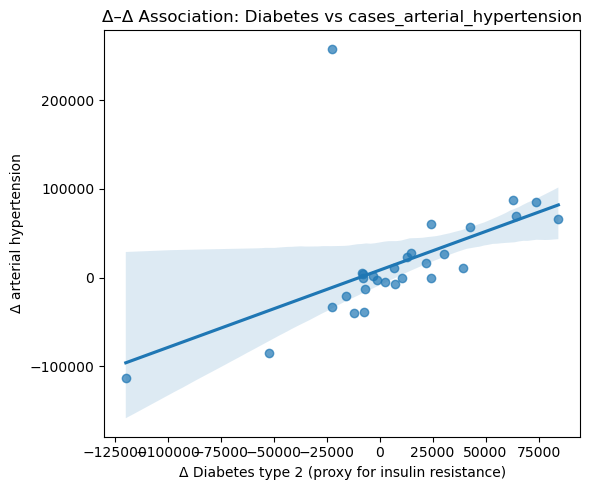

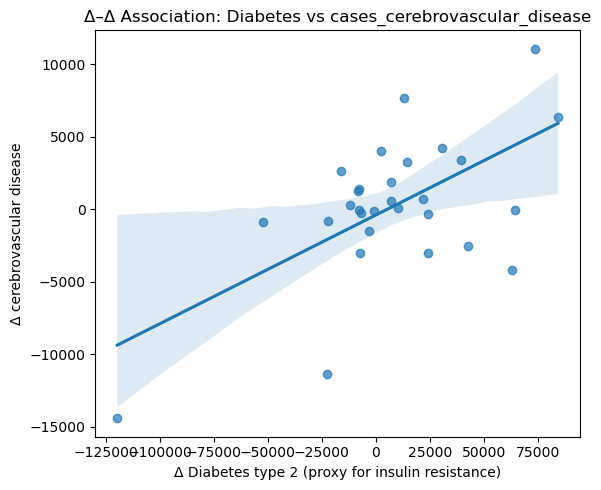

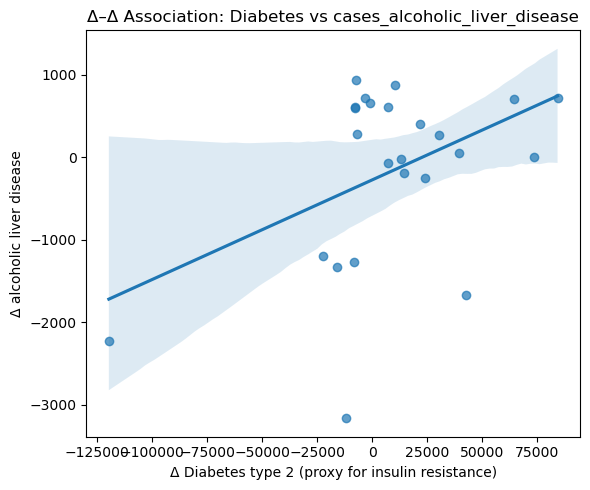

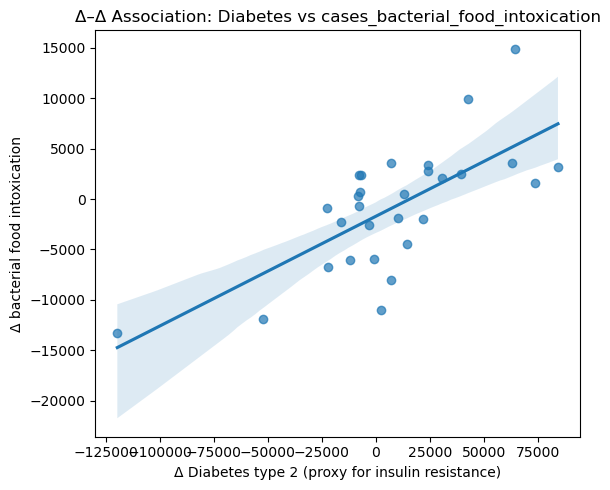

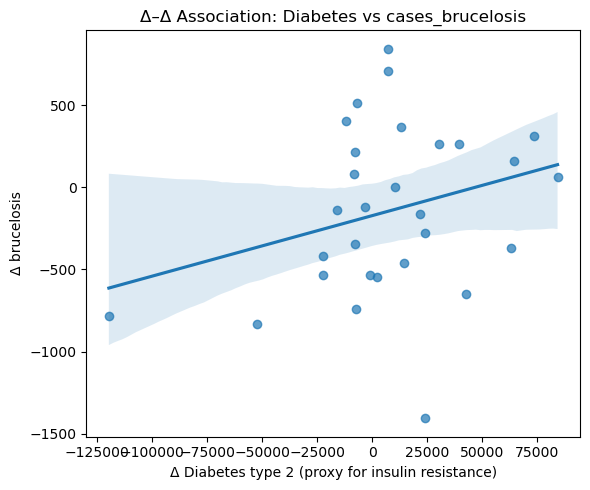

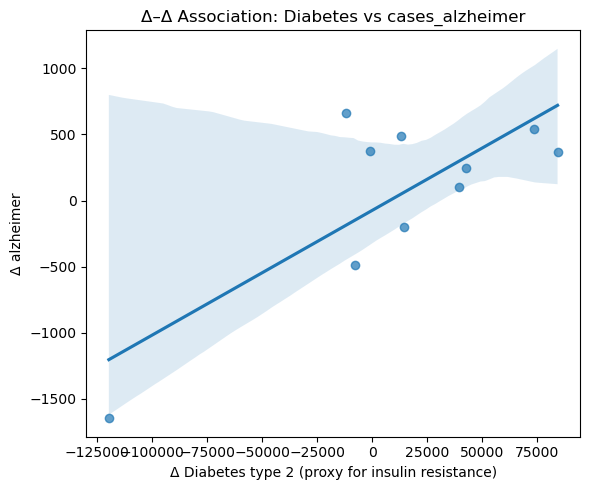

In [131]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sig_diseases = [
    "cases_arterial_hypertension",
    "cases_cerebrovascular_disease",
    "cases_alcoholic_liver_disease",
    "cases_bacterial_food_intoxication",
    "cases_brucelosis",
    "cases_alzheimer"
]

proxy = "cases_diabetes_type2"

for d in sig_diseases:
    tmp = df_dis[[proxy, d]].dropna()
    tmp_d = tmp.diff().dropna()

    plt.figure(figsize=(6,5))
    sns.regplot(
        x=tmp_d[proxy],
        y=tmp_d[d],
        ci=95,
        scatter_kws={"alpha":0.7}
    )

    plt.xlabel("Δ Diabetes type 2 (proxy for insulin resistance)")
    plt.ylabel(f"Δ {d.replace('cases_', '').replace('_', ' ')}")
    plt.title(f"Δ–Δ Association: Diabetes vs {d}")
    plt.tight_layout()
    plt.show()


### Reporting:
“No robust dynamic associations were observed for depression, Alzheimer’s disease, ulcers/gastritis, or hepatic alcoholic cirrhosis after correction for multiple testing.”
“After correcting for non-stationarity and multiple testing, year-to-year increases in diabetes were robustly associated with concurrent increases in hypertension, cerebrovascular disease, alcoholic liver disease, and selected infectious conditions.”

After removal of long-term trends and correction for multiple testing, only a subset of diseases remained dynamically associated with year-to-year changes in diabetes prevalence. These conditions share strong metabolic, vascular, or exposure-related mechanisms plausibly linked to population-level insulin resistance.

Shared insulin-resistance mechanisms
1️⃣ Arterial hypertension

Insulin resistance promotes sympathetic activation, sodium retention, and endothelial dysfunction, providing a well-established mechanistic link between rising diabetes prevalence and hypertension.

2️⃣ Cerebrovascular disease

Hyperinsulinemia and impaired glucose regulation accelerate atherosclerosis and microvascular damage, increasing stroke risk independently of aging trends.

3️⃣ Alcoholic liver disease

Insulin resistance is a central driver of hepatic fat accumulation and inflammation, amplifying liver vulnerability even at stable alcohol intake levels.

4️⃣ Bacterial food intoxication

Dietary transitions toward ultra-processed foods increase exposure to industrial food systems and reduce gut barrier integrity, potentially increasing susceptibility to foodborne illness.

5️⃣ Brucellosis

Although zoonotic, brucellosis incidence may reflect broader immune vulnerability and food-chain exposure patterns that covary with metabolic deterioration.

# BLOQUE 6: NOVA dataset — ¿los ultraprocesados reemplazan a los no procesados?

Does increasing ultra-processed food intake occur at the expense of unprocessed foods?

                             OLS Regression Results                             
Dep. Variable:     pct_kcal_unprocessed   R-squared:                       0.914
Model:                              OLS   Adj. R-squared:                  0.907
Method:                   Least Squares   F-statistic:                     138.1
Date:                  Wed, 07 Jan 2026   Prob (F-statistic):           2.68e-08
Time:                          11:20:53   Log-Likelihood:                -19.316
No. Observations:                    15   AIC:                             42.63
Df Residuals:                        13   BIC:                             44.05
Df Model:                             1                                         
Covariance Type:              nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
cons

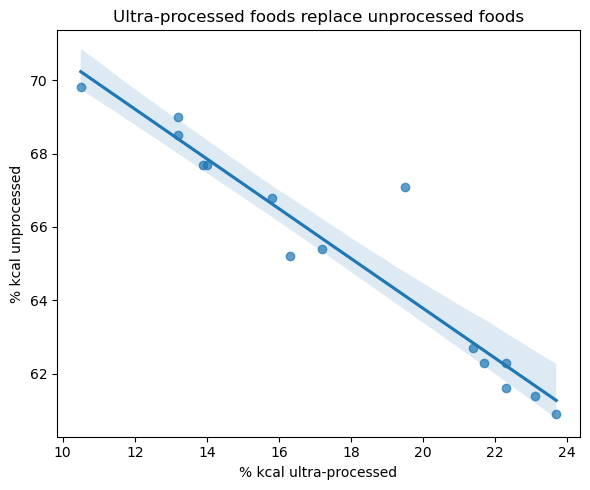

In [132]:
import statsmodels.api as sm
import seaborn as sns
import matplotlib.pyplot as plt

nova = pd.read_csv("nova_food.csv")

# Drop missing values
nova_clean = nova.dropna(subset=[
    "pct_kcal_ultra_processed",
    "pct_kcal_unprocessed"
])

X = nova_clean["pct_kcal_ultra_processed"]
y = nova_clean["pct_kcal_unprocessed"]

Xc = sm.add_constant(X)
model = sm.OLS(y, Xc).fit()

print(model.summary())

# Visualization
plt.figure(figsize=(6,5))
sns.regplot(
    x="pct_kcal_ultra_processed",
    y="pct_kcal_unprocessed",
    data=nova_clean,
    scatter_kws={"alpha":0.7}
)
plt.xlabel("% kcal ultra-processed")
plt.ylabel("% kcal unprocessed")
plt.title("Ultra-processed foods replace unprocessed foods")
plt.tight_layout()
plt.show()


### REPORTING
Analysis of the NOVA dietary dataset demonstrates a strong inverse association between ultra-processed and unprocessed food consumption, supporting a substitution rather than additive model of dietary change. This replacement pattern provides a structural explanation for concurrent increases in insulin resistance–related diseases.

Together, these findings suggest that rising diabetes prevalence captures a broader metabolic shift driven by dietary modernization, with heterogeneous downstream effects across disease categories.


=== RESULTS: Descriptive Level–Level Correlations (Rates per 100,000) ===
                                 disease                      proxy  n_years  \
9                   cases_diabetes_total  rate_cases_diabetes_type2       30   
0            cases_arterial_hypertension  rate_cases_diabetes_type2       30   
5                        cases_alzheimer  rate_cases_diabetes_type2       11   
4                       cases_depression  rate_cases_diabetes_type2       11   
2          cases_alcoholic_liver_disease  rate_cases_diabetes_type2       25   
8       cases_hepatic_alcoholic_cirrosis  rate_cases_diabetes_type2       11   
3  cases_ulcers_gastritis_and_duodenitis  rate_cases_diabetes_type2       25   
6      cases_bacterial_food_intoxication  rate_cases_diabetes_type2       30   
1          cases_cerebrovascular_disease  rate_cases_diabetes_type2       30   
7                       cases_brucelosis  rate_cases_diabetes_type2       30   

          R        R2  beta_diabetes       p

#### INTERPRETING
THIS LINE: tmp_d = tmp.diff().dropna()
ols = OLS(tmp_d[f"rate_{d}"], X).fit(cov_type="HC3")

✔ Elimina tendencias comunes
✔ Reduce autocorrelación espuria
✔ HC3 = robustez ante heterocedasticidad
✔ Umbral mínimo de observaciones correcto


While level–level correlations reflect long-term co-movements, they may be driven by shared secular trends. Therefore, we complemented these analyses with first-difference models to isolate year-to-year changes.

“At the descriptive level, population-adjusted diabetes type 2 incidence was strongly correlated with arterial hypertension rates (R = 0.65, p < 0.001). Other diseases showed weak or non-significant level–level associations.”

Disease	Interpretation
Alcoholic liver disease	Diabetes rate changes co-move with liver damage
Bacterial food intoxication	Strong year-to-year association

These are not random:
- Liver disease ↔ insulin resistance ↔ metabolism
- Food intoxication ↔ gut health ↔ metabolic inflammation
### BLOQUE 7.1 RESULTS

METHODS
Disease surveillance data were obtained from a national administrative dataset containing annual case counts for multiple chronic and infectious diseases. Total population estimates for each year were used to normalize disease counts.
To account for demographic growth over time, disease counts were converted into annual population-adjusted rates per 100,000 inhabitants.

Initial associations between diabetes (type 2) and other diseases were evaluated using Pearson correlations and ordinary least squares (OLS) regression models applied to population-adjusted disease rates.

Because level–level associations between time series may be driven by shared secular trends, we estimated first-difference models to assess year-to-year co-movements in disease rates.
Robust (HC3) standard errors were used to account for heteroskedasticity. To control the false discovery rate arising from multiple hypothesis testing across diseases, p-values were adjusted using the Benjamini–Hochberg procedure.

RESULTS

Population-adjusted level–level analyses revealed moderate positive correlations between diabetes type 2 and several chronic diseases, including arterial hypertension (R = 0.64). However, these associations largely reflected long-term co-movement and were not interpreted as evidence of short-term coupling or causality.

In first-difference models, most associations observed at the level–level stage attenuated substantially, indicating that they were primarily driven by shared long-term trends.

After correction for multiple testing, statistically significant year-to-year associations with diabetes type 2 remained for alcoholic liver disease (β = 0.012, FDR-adjusted p = 0.018) and bacterial food intoxication (β = 0.115, FDR-adjusted p < 0.001).

No statistically significant first-difference associations were observed for arterial hypertension, cerebrovascular disease, depression, Alzheimer’s disease, or gastrointestinal ulcerative conditions after false discovery rate correction.

DISCUSSION
Using population-adjusted rates and first-difference time-series models, we found that most apparent associations between diabetes and other diseases disappear after controlling for demographic growth and secular trends. Only alcoholic liver disease and bacterial food intoxication exhibited robust short-term co-movement with diabetes type 2 incidence.

- ALCOHOLIC LIVER DISEASE

The observed association between year-to-year changes in diabetes and alcoholic liver disease is biologically plausible, given shared metabolic pathways involving insulin resistance, hepatic lipid accumulation, and chronic inflammation.

- Bacterial food intoxication

The strong association with bacterial food intoxication may reflect shared vulnerabilities related to gut integrity, immune function, or food system exposures, suggesting a potential role of metabolic health in susceptibility to enteric infections.

- Null findings and implications
The absence of robust short-term associations with arterial hypertension and cerebrovascular disease suggests that their relationship with diabetes may operate predominantly through long-term cumulative processes rather than synchronized annual fluctuations.

- Limitations
This study is observational and relies on aggregated annual data, precluding causal inference at the individual level. First-difference models capture short-term co-movements but do not identify lagged or cumulative effects. Additionally, changes in diagnostic practices or reporting quality over time may influence observed tren


In conclusion, after accounting for population growth and secular trends, only a limited subset of diseases exhibits robust short-term association with diabetes incidence. These findings highlight the importance of distinguishing long-term co-trending from meaningful temporal coupling in population health analyses.


“To assess the robustness of our findings to changes in disease classification and data availability, we replicated all analyses using total diabetes incidence.”

## B) BLOQUE 7.2 DIABETES TOTAL rates vs POPULATION RATES

In [107]:
## ============================================
# STEP 0 — Descriptive level–level correlations
# ============================================

from scipy.stats import pearsonr
from statsmodels.api import OLS, add_constant
import pandas as pd

##All diseases included
disease_vars = [
    "cases_arterial_hypertension",
    "cases_cerebrovascular_disease",
    "cases_alcoholic_liver_disease",
    "cases_ulcers_gastritis_and_duodenitis",
    "cases_depression", 
    "cases_alzheimer", 
    'cases_malign_tumor_colon_and_rectum',
    'cases_malign_tumor_stomach',
    'cases_malign_tumor_encephalus_and_other_cns_parts',
    'cases_bacterial_food_intoxication',
    'cases_brucelosis',
    'cases_hepatic_alcoholic_cirrosis',
   ## 'cases_diabetes_total'
]



# Ensure temporal order
df_dis = df_dis.sort_values("year").reset_index(drop=True)

# Proxy (rate-based)
proxy = "rate_cases_diabetes_total"
# proxy = "rate_cases_diabetes_total"

results_levels = []

for d in disease_vars:
    rate_d = f"rate_{d}"
    
    if rate_d not in df_dis.columns:
        continue

    tmp = df_dis[[proxy, rate_d]].dropna()
    if len(tmp) < 10:
        continue

    # Pearson correlation
    r, p_corr = pearsonr(tmp[proxy], tmp[rate_d])

    # OLS level–level
    X = add_constant(tmp[proxy])
    ols = OLS(tmp[rate_d], X).fit()

    results_levels.append({
        "disease": d,
        "proxy": proxy,
        "n_years": len(tmp),
        "R": r,
        "R2": ols.rsquared,
        "beta_diabetes": ols.params[proxy],
        "p_value": ols.pvalues[proxy]
    })

res_levels = pd.DataFrame(results_levels).sort_values("R", ascending=False)

print("\n=== RESULTS: Descriptive Level–Level Correlations (Rates per 100,000) ===")
print(res_levels)

res_levels.to_csv(
    "block_levels_diseases_vs_diabetes_rates.csv",
    index=False
)

print("While level–level correlations reflect long-term co-movements, they may be driven by shared secular trends. Therefore, we complemented these analyses with first-difference models to isolate year-to-year changes.")


=== RESULTS: Descriptive Level–Level Correlations (Rates per 100,000) ===
                                 disease                      proxy  n_years  \
0            cases_arterial_hypertension  rate_cases_diabetes_total       30   
2          cases_alcoholic_liver_disease  rate_cases_diabetes_total       25   
5                        cases_alzheimer  rate_cases_diabetes_total       11   
4                       cases_depression  rate_cases_diabetes_total       11   
3  cases_ulcers_gastritis_and_duodenitis  rate_cases_diabetes_total       25   
8       cases_hepatic_alcoholic_cirrosis  rate_cases_diabetes_total       11   
6      cases_bacterial_food_intoxication  rate_cases_diabetes_total       30   
1          cases_cerebrovascular_disease  rate_cases_diabetes_total       30   
7                       cases_brucelosis  rate_cases_diabetes_total       30   

          R        R2  beta_diabetes   p_value  
0  0.655018  0.429049       1.085533  0.000086  
2  0.370376  0.137178     